# pcb_rabi

Rabi data from `rabi.py` runs on the new diamond / PCB, from `D:\rabi\<name>`.

Pulse lengths are the ones the AWG actually played (`played_us()`): `rabi.py` rounds each tau_mw to a whole 1 ns sample, so the 2.5 ns-step runs played 5, 7, 10, 12, ... ns, not the 5, 7.5, 10, 12.5, ... ns saved in `_rabi_mw_us.npy`.

In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")

RABI_DATA_DIR = Path(r"D:\rabi")
OVERLOAD_PATTERN = re.compile(r"OVERLOAD at tau_mw=([0-9.]+) us")


AWG_SAMPLE_RATE_HZ = 1e9


def played_us(mw_us, sample_rate_hz=AWG_SAMPLE_RATE_HZ):
    """Pulse lengths the AWG actually played: rabi.py's _us_to_samples() rounds each tau_mw to a whole
    sample (1 ns), so e.g. a nominal 7.5 ns plays as 7 ns (7.5 comes out of the float maths as 7.4999...)."""
    return np.array([max(1, round(v * 1e-6 * sample_rate_hz)) for v in np.atleast_1d(mw_us)]) / sample_rate_hz * 1e6


def load_rabi(name, data_dir=RABI_DATA_DIR):
    """Load a single `rabi.py run` result.

    Returns
    -------
    dict with mw_us (played pulse lengths, µs -- see played_us(); mw_us_nominal is the saved grid),
    x, y, reflected_dbm, ref_freq_hz (1D np.ndarray, V for x/y),
    reference_unlock (bool array), overload (bool array: points whose reading came
    right after an overload-triggered sensitivity change, parsed from the run's log)
    and metadata (dict of str).
    """
    d = data_dir / name
    prefix = f"{name}_rabi"
    run = {key: np.load(d / f"{prefix}_{key}.npy")
           for key in ("mw_us", "x", "y", "reflected_dbm", "ref_freq_hz", "reference_unlock")}
    lines = (d / f"{prefix}_metadata.txt").read_text().splitlines()
    run["metadata"] = dict(line.split("=", 1) for line in lines if "=" in line)

    run["mw_us_nominal"] = run["mw_us"]
    run["mw_us"] = played_us(run["mw_us_nominal"])
    run["overload"] = np.zeros(len(run["mw_us"]), dtype=bool)
    log_path = data_dir / "logs" / f"{prefix}.txt"
    if log_path.exists():
        for tau_us in map(float, OVERLOAD_PATTERN.findall(log_path.read_text())):
            run["overload"] |= np.isclose(run["mw_us_nominal"], tau_us, atol=5e-4)
    else:
        print(f"no log at {log_path} -- overload points not marked")
    return run


def principal_axis(x, y):
    """Unit vector (and angle in degrees) of the direction of largest variance in the X/Y plane."""
    xy = np.column_stack([x - x.mean(), y - y.mean()])
    _, _, vt = np.linalg.svd(xy, full_matrices=False)
    axis = vt[0]
    return axis, np.degrees(np.arctan2(axis[1], axis[0]))

## pcb_rabi1 (2.859 GHz, -20 dBm, coil 1 A, phase 0)

The phase wasn't calibrated, so the signal is split between X and Y. "Projected" is (X, Y) projected onto the direction of largest variance (SVD) -- what a calibrated phase would put in X. Its sign is arbitrary.

Gray points are readings taken right after an overload-triggered sensitivity change (from the run's log); they're left out of the lines and the direction fit.

In [2]:
rabi_name = "pcb_rabi1"
run = load_rabi(rabi_name)
good = ~run["overload"]

for key, value in run["metadata"].items():
    print(f"{key}={value}")
print()
print(f"{len(run['mw_us'])} points, {run['mw_us'].min() * 1e3:.0f}-{run['mw_us'].max() * 1e3:.0f} ns")
print(f"reference unlocks: {int(run['reference_unlock'].sum())}")
print(f"overload points: {int(run['overload'].sum())} at "
      f"{', '.join(f'{t:.0f}' for t in run['mw_us'][run['overload']] * 1e3)} ns")
print(f"SR830 reference: {np.nanmin(run['ref_freq_hz']):.6f}-{np.nanmax(run['ref_freq_hz']):.6f} Hz")

axis, angle_deg = principal_axis(run["x"][good], run["y"][good])
print(f"main signal direction (overload points excluded): {angle_deg:.1f} deg from X")

freq_hz=2859000000.0
drive_power_dbm=-20.0
n_reps=250
laser_us=2.0
pre_us=1.0
post_us=1.0
time_constant_s=0.1
settle_periods=5.0
settle_time_constants=9.0
sensitivity_v=2e-05
phase_deg=0.0
coil_current_a=1.0
constant_shot_period=1
pad_min_us=0.1

100 points, 5-500 ns
reference unlocks: 0
overload points: 7 at 35, 90, 135, 150, 200, 315, 400 ns
SR830 reference: 434.790000-434.790000 Hz
main signal direction (overload points excluded): 17.5 deg from X


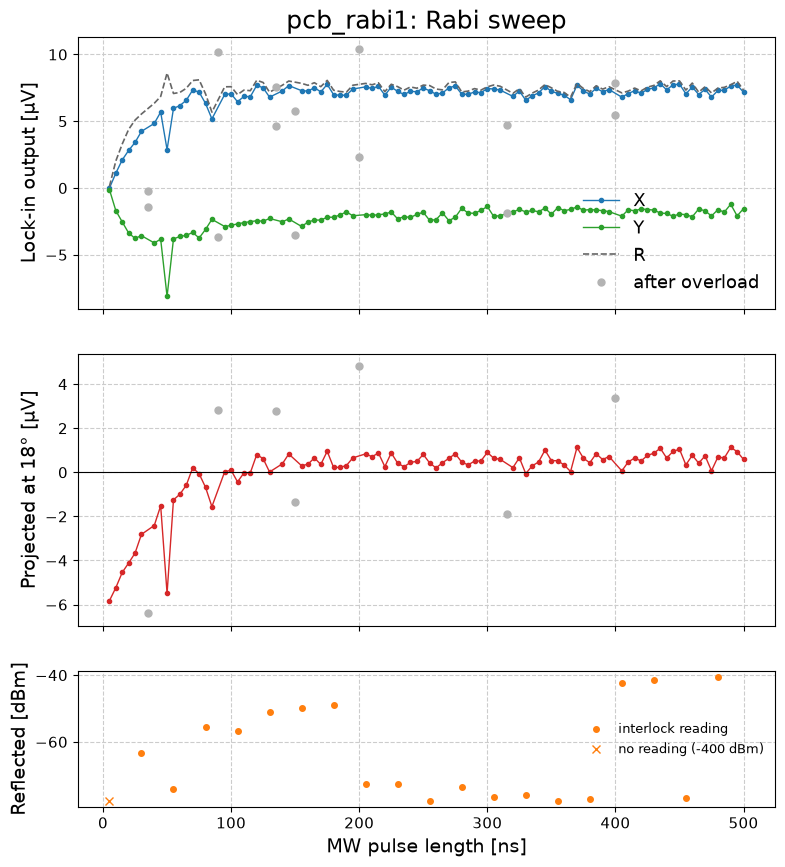

In [3]:
t_ns = run["mw_us"] * 1e3
x_uv, y_uv = run["x"] * 1e6, run["y"] * 1e6
r_uv = np.hypot(x_uv, y_uv)
proj_uv = (x_uv - x_uv[good].mean()) * axis[0] + (y_uv - y_uv[good].mean()) * axis[1]
bad = run["overload"]

refl = run["reflected_dbm"]
checked = np.isfinite(refl)
no_reading = checked & (refl <= -300)

fig, axs = plt.subplot_mosaic([["xyr"], ["proj"], ["diag"]], sharex=True, figsize=(9, 10),
                              height_ratios=[2, 2, 1])
axs["xyr"].plot(t_ns[good], x_uv[good], "o-", ms=3, lw=1, color="C0", label="X")
axs["xyr"].plot(t_ns[good], y_uv[good], "o-", ms=3, lw=1, color="C2", label="Y")
axs["xyr"].plot(t_ns[good], r_uv[good], "--", lw=1.2, color="0.4", label="R")
if bad.any():
    axs["xyr"].plot(t_ns[bad], x_uv[bad], "o", ms=5, color="0.7", label="after overload")
    axs["xyr"].plot(t_ns[bad], y_uv[bad], "o", ms=5, color="0.7")
axs["xyr"].set_ylabel("Lock-in output [µV]")
axs["xyr"].set_title(f"{rabi_name}: Rabi sweep")
axs["xyr"].legend()

axs["proj"].plot(t_ns[good], proj_uv[good], "o-", ms=3, lw=1, color="C3")
if bad.any():
    axs["proj"].plot(t_ns[bad], proj_uv[bad], "o", ms=5, color="0.7")
axs["proj"].axhline(0, color="k", lw=0.8)
axs["proj"].set_ylabel(f"Projected at {angle_deg:.0f}° [µV]")

axs["diag"].plot(t_ns[checked & ~no_reading], refl[checked & ~no_reading], "o", ms=4, color="C1",
                  label="interlock reading")
if no_reading.any():
    axs["diag"].plot(t_ns[no_reading], np.full(no_reading.sum(), np.nanmin(refl[checked & ~no_reading])),
                      "x", ms=6, color="C1", label="no reading (-400 dBm)")
unlock = run["reference_unlock"].astype(bool)
if unlock.any():
    for t in t_ns[unlock]:
        axs["diag"].axvline(t, color="r", lw=1, alpha=0.5)
axs["diag"].set_ylabel("Reflected [dBm]")
axs["diag"].set_xlabel("MW pulse length [ns]")
axs["diag"].legend(fontsize=9)
plt.show()

## pcb_rabi2: on peak (2.859 GHz) vs off peak (2.830 GHz)

Same settings otherwise (-10 dBm, coil 1 A, 5-100 ns, phase 0). Anything that's the same in both isn't the spin; the difference panel shows what depends on being on the line. Gray points came right after an overload range change; they're left out of the lines and the difference.

on peak, 2.859 GHz (pcb_rabi2): -10.0 dBm, coil 1.0 A, overload points at 10, 20 ns, reference unlocks 0
off peak, 2.830 GHz (pcb_rabi2_check): -10.0 dBm, coil 1.0 A, overload points at none ns, reference unlocks 0


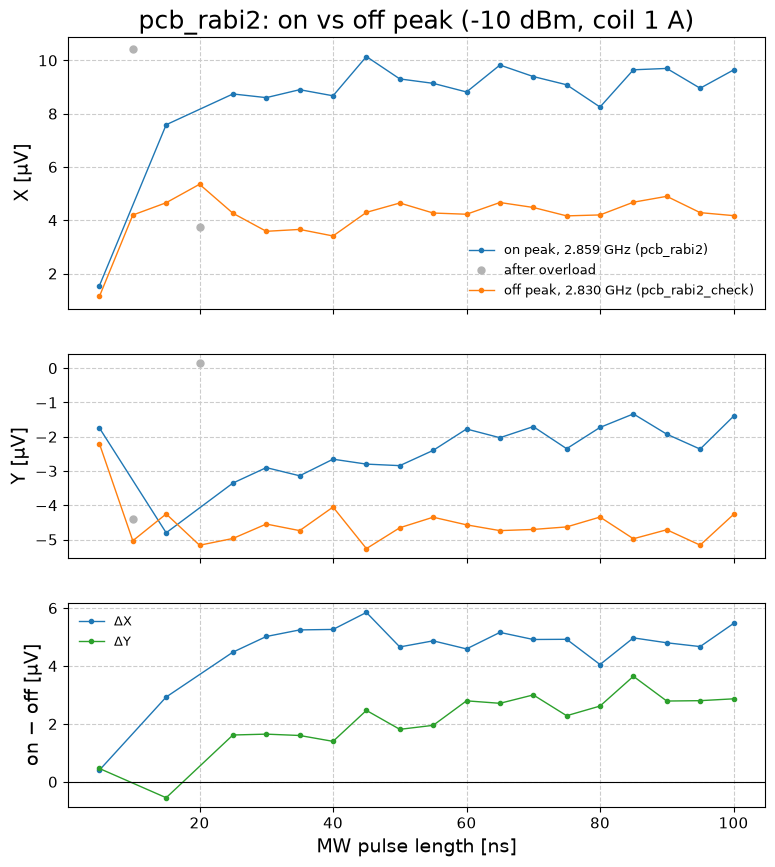

In [4]:
runs_cmp = {"on peak, 2.859 GHz (pcb_rabi2)": load_rabi("pcb_rabi2"),
            "off peak, 2.830 GHz (pcb_rabi2_check)": load_rabi("pcb_rabi2_check")}
(on, off) = runs_cmp.values()
assert np.allclose(on["mw_us"], off["mw_us"]), "pulse-length grids differ"
t_ns = on["mw_us"] * 1e3
for label, r in runs_cmp.items():
    print(f"{label}: {r['metadata']['drive_power_dbm']} dBm, coil {r['metadata']['coil_current_a']} A, "
          f"overload points at {', '.join(f'{t:.0f}' for t in r['mw_us'][r['overload']] * 1e3) or 'none'} ns, "
          f"reference unlocks {int(r['reference_unlock'].sum())}")

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["diff"]], sharex=True, figsize=(9, 10),
                              height_ratios=[2, 1.5, 1.5])
for i, (label, r) in enumerate(runs_cmp.items()):
    ok, bad = ~r["overload"], r["overload"]
    for key in ("x", "y"):
        v_uv = r[key] * 1e6
        axs[key].plot(t_ns[ok], v_uv[ok], "o-", ms=3, lw=1, color=f"C{i}",
                      label=label if key == "x" else None)
        axs[key].plot(t_ns[bad], v_uv[bad], "o", ms=5, color="0.7",
                      label="after overload" if (key == "x" and i == 0 and bad.any()) else None)
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("pcb_rabi2: on vs off peak (-10 dBm, coil 1 A)")
axs["x"].legend(fontsize=9)
axs["y"].set_ylabel("Y [µV]")

both_ok = ~on["overload"] & ~off["overload"]
axs["diff"].plot(t_ns[both_ok], (on["x"] - off["x"])[both_ok] * 1e6, "o-", ms=3, lw=1, color="C0", label="ΔX")
axs["diff"].plot(t_ns[both_ok], (on["y"] - off["y"])[both_ok] * 1e6, "o-", ms=3, lw=1, color="C2", label="ΔY")
axs["diff"].axhline(0, color="k", lw=0.8)
axs["diff"].set_ylabel("on − off [µV]")
axs["diff"].set_xlabel("MW pulse length [ns]")
axs["diff"].legend(fontsize=9)
plt.show()

## Objective-diamond distance: pcb_rabi2_rerun, pcb_rabi3 (further), pcb_rabi4 (closer)

All at 2.859 GHz, -10 dBm, coil 1 A, phase 0, with the CW interlock checks; only the objective-to-diamond distance changes (PCB-diamond geometry unchanged). The original pcb_rabi2 (same settings and focus as the rerun, old interlock code) is shown dashed for repeatability. The bottom panel scales each R curve to its own plateau, to compare rise times independent of signal size.

pcb_rabi2 (original focus, old code): 20 points, 5-100 ns, overload at 10, 20 ns; mean X, Y for t >= 40 ns: 9.27, -2.10 µV; in-sweep reflected -68.75 dBm
pcb_rabi2_rerun (original focus): 16 points, 5-80 ns, overload at none ns; mean X, Y for t >= 40 ns: 9.72, -2.59 µV; in-sweep reflected -11.34 dBm
pcb_rabi3 (objective further): 12 points, 5-60 ns, overload at 30, 55 ns; mean X, Y for t >= 40 ns: 4.30, -0.04 µV; in-sweep reflected -11.18 dBm
pcb_rabi4 (objective closer): 12 points, 5-60 ns, overload at 10, 15, 30 ns; mean X, Y for t >= 40 ns: 127.61, -57.48 µV; in-sweep reflected -10.11 dBm


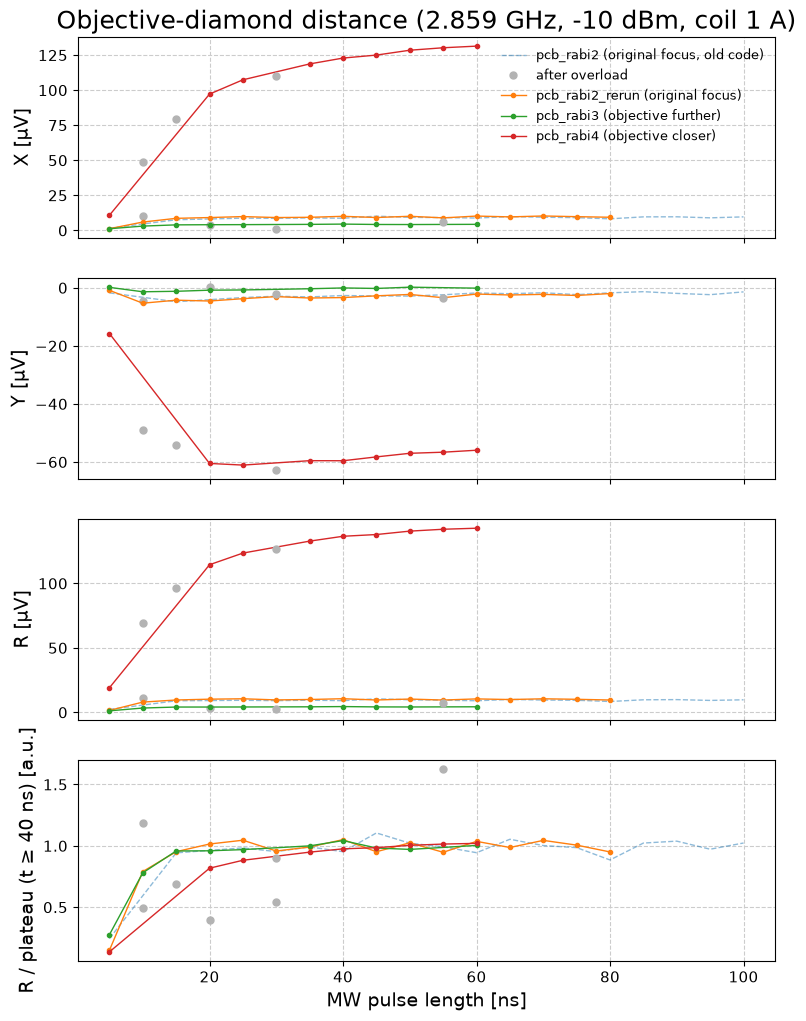

In [5]:
runs_pos = {"pcb_rabi2 (original focus, old code)": ("pcb_rabi2", "--", 0.5),
            "pcb_rabi2_rerun (original focus)": ("pcb_rabi2_rerun", "o-", 1.0),
            "pcb_rabi3 (objective further)": ("pcb_rabi3_diamond_further", "o-", 1.0),
            "pcb_rabi4 (objective closer)": ("pcb_rabi4_diamond_toward_objective", "o-", 1.0)}
pos = {label: load_rabi(name) for label, (name, _, _) in runs_pos.items()}
for label, r in pos.items():
    t = r["mw_us"] * 1e3
    ok = ~r["overload"]
    late = ok & (t >= 40)
    refl = r["reflected_dbm"][np.isfinite(r["reflected_dbm"]) & (r["reflected_dbm"] > -300)]
    print(f"{label}: {len(t)} points, {t.min():.0f}-{t.max():.0f} ns, overload at "
          f"{', '.join(f'{v:.0f}' for v in t[r['overload']]) or 'none'} ns; "
          f"mean X, Y for t >= 40 ns: {r['x'][late].mean() * 1e6:.2f}, {r['y'][late].mean() * 1e6:.2f} µV; "
          f"in-sweep reflected {refl.mean():.2f} dBm")

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["r"], ["rnorm"]], sharex=True, figsize=(9, 12))
overload_labelled = False
for i, (label, r) in enumerate(pos.items()):
    _, style, alpha = runs_pos[label]
    t = r["mw_us"] * 1e3
    ok, bad = ~r["overload"], r["overload"]
    x_uv, y_uv = r["x"] * 1e6, r["y"] * 1e6
    r_uv = np.hypot(x_uv, y_uv)
    plateau = r_uv[ok & (t >= 40)].mean()
    for key, v in (("x", x_uv), ("y", y_uv), ("r", r_uv), ("rnorm", r_uv / plateau)):
        axs[key].plot(t[ok], v[ok], style, ms=3, lw=1, color=f"C{i}", alpha=alpha,
                      label=label if key == "x" else None)
        if bad.any():
            axs[key].plot(t[bad], v[bad], "o", ms=5, color="0.7",
                          label="after overload" if (key == "x" and not overload_labelled) else None)
    overload_labelled |= bad.any()
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("Objective-diamond distance (2.859 GHz, -10 dBm, coil 1 A)")
axs["x"].legend(fontsize=9)
axs["y"].set_ylabel("Y [µV]")
axs["r"].set_ylabel("R [µV]")
axs["rnorm"].set_ylabel("R / plateau (t ≥ 40 ns) [a.u.]")
axs["rnorm"].set_xlabel("MW pulse length [ns]")
plt.show()

## Objective closer: power and line comparison

All at the closer focus (same as pcb_rabi4), coil 1 A, phase 0. pcb_rabi4_more_run repeats the lower line (2.859 GHz) at -20 dBm with a fixed 200 µV range; pcb_rabi4_more_run2 drives the upper line (2.880 GHz) at -10 dBm. Bottom panel: each R curve scaled to its own plateau, to compare rise times.

pcb_rabi4: 2.859 GHz, -10 dBm: 12 points, 5-60 ns, overload at 10, 15, 30 ns; mean X, Y for t >= 40 ns: 127.6, -57.5 µV; CW reflected -10.11 dBm
more_run: 2.859 GHz, -20 dBm: 24 points, 5-120 ns, overload at none ns; mean X, Y for t >= 40 ns: 82.7, -56.4 µV; CW reflected -20.00 dBm
more_run2: 2.880 GHz, -10 dBm: 16 points, 5-80 ns, overload at none ns; mean X, Y for t >= 40 ns: 130.4, -56.2 µV; CW reflected -13.84 dBm


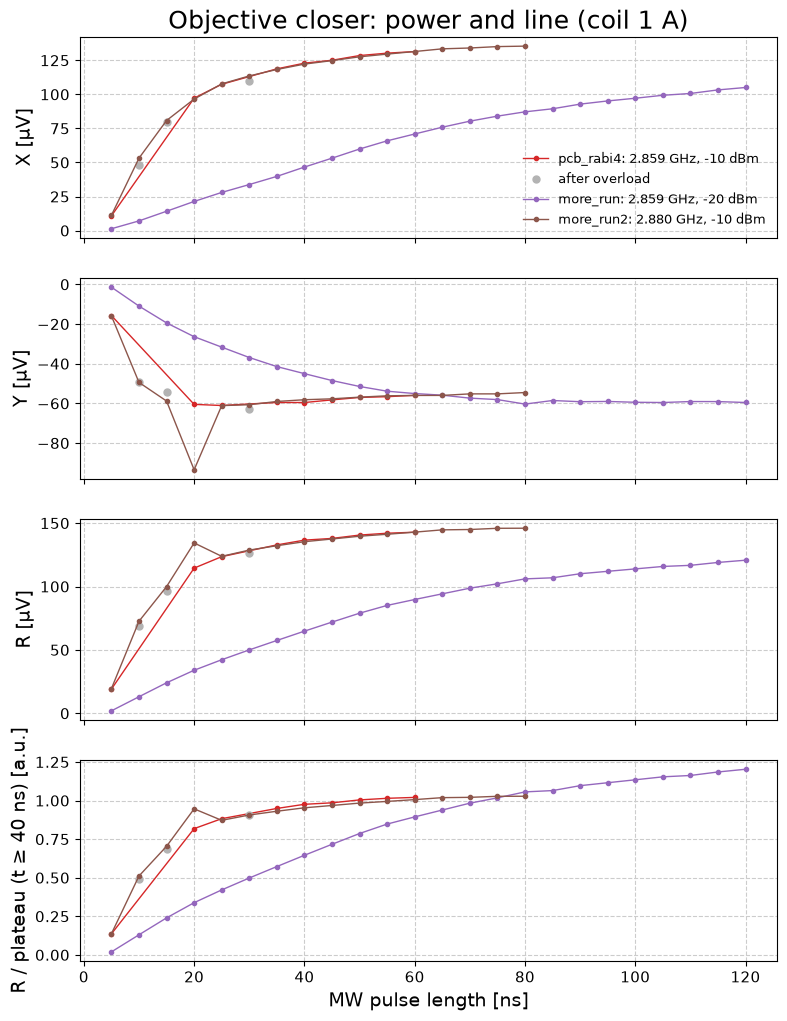

In [6]:
runs_close = {"pcb_rabi4: 2.859 GHz, -10 dBm": "pcb_rabi4_diamond_toward_objective",
              "more_run: 2.859 GHz, -20 dBm": "pcb_rabi4_more_run",
              "more_run2: 2.880 GHz, -10 dBm": "pcb_rabi4_more_run2"}
close = {label: load_rabi(name) for label, name in runs_close.items()}
for label, r in close.items():
    t = r["mw_us"] * 1e3
    ok = ~r["overload"]
    late = ok & (t >= 40)
    refl = r["reflected_dbm"][np.isfinite(r["reflected_dbm"]) & (r["reflected_dbm"] > -300)]
    print(f"{label}: {len(t)} points, {t.min():.0f}-{t.max():.0f} ns, overload at "
          f"{', '.join(f'{v:.0f}' for v in t[r['overload']]) or 'none'} ns; "
          f"mean X, Y for t >= 40 ns: {r['x'][late].mean() * 1e6:.1f}, {r['y'][late].mean() * 1e6:.1f} µV; "
          f"CW reflected {refl.mean():.2f} dBm")

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["r"], ["rnorm"]], sharex=True, figsize=(9, 12))
overload_labelled = False
for i, (label, r) in enumerate(close.items()):
    t = r["mw_us"] * 1e3
    ok, bad = ~r["overload"], r["overload"]
    x_uv, y_uv = r["x"] * 1e6, r["y"] * 1e6
    r_uv = np.hypot(x_uv, y_uv)
    plateau = r_uv[ok & (t >= 40)].mean()
    for key, v in (("x", x_uv), ("y", y_uv), ("r", r_uv), ("rnorm", r_uv / plateau)):
        axs[key].plot(t[ok], v[ok], "o-", ms=3, lw=1, color=f"C{i + 3}",
                      label=label if key == "x" else None)
        if bad.any():
            axs[key].plot(t[bad], v[bad], "o", ms=5, color="0.7",
                          label="after overload" if (key == "x" and not overload_labelled) else None)
    overload_labelled |= bad.any()
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("Objective closer: power and line (coil 1 A)")
axs["x"].legend(fontsize=9)
axs["y"].set_ylabel("Y [µV]")
axs["r"].set_ylabel("R [µV]")
axs["rnorm"].set_ylabel("R / plateau (t ≥ 40 ns) [a.u.]")
axs["rnorm"].set_xlabel("MW pulse length [ns]")
plt.show()

## Upper line (2.880 GHz, -10 dBm): closer vs even closer focus

Each focus position's sweep was taken in pieces (5-80 ns, then 80-120 ns) and is stitched here. At the even-closer focus the 80-120 ns piece was taken twice: `_cont` (float32 upload) and `_cont_script_change` (int16 upload). Bottom panel scales each focus's R to its own plateau (t ≥ 100 ns).

closer (pcb_rabi4): R at 80 ns across runs: 146.0, 146.6 µV
closer (pcb_rabi4): R plateau (t >= 100 ns) 147.3 µV
even closer (pcb_rabi5): R at 80 ns across runs: 176.3, 185.6, 185.2 µV
even closer (pcb_rabi5): R at 120 ns across runs: 213.8, 213.5, 222.1 µV
even closer (pcb_rabi5): R plateau (t >= 100 ns) 221.9 µV


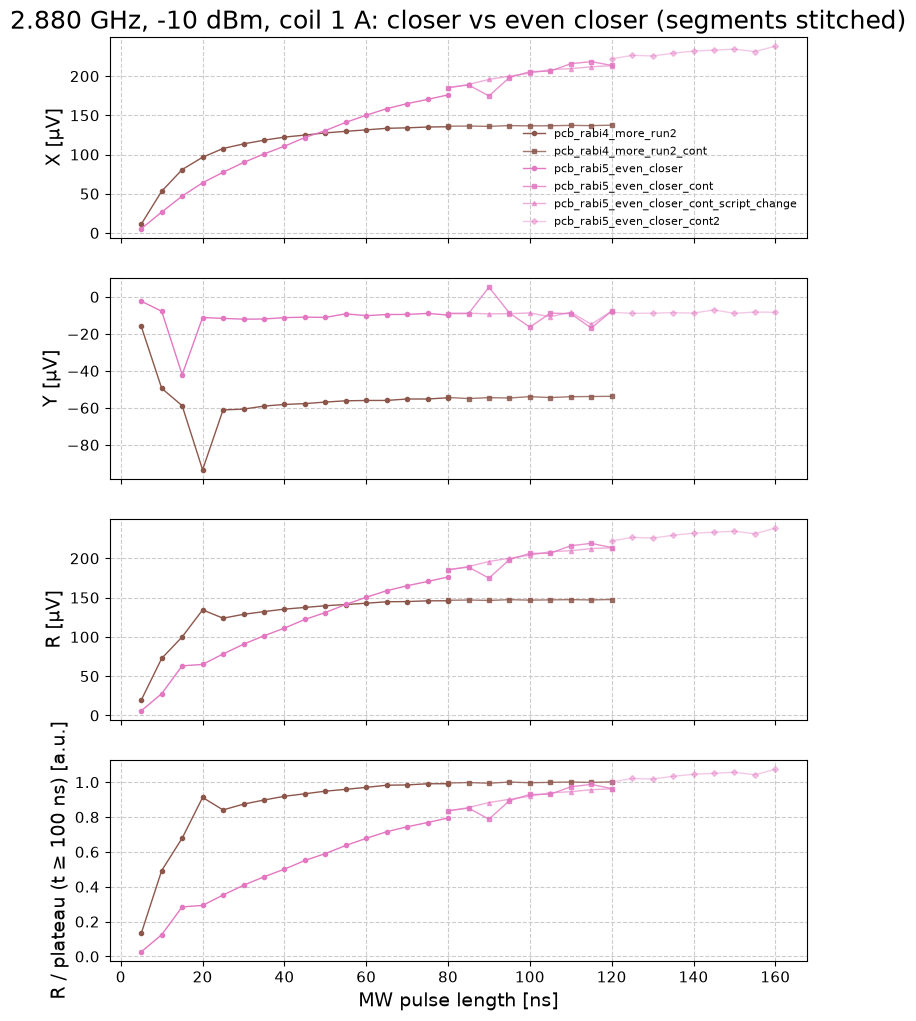

In [7]:
focus_sets = {
    "closer (pcb_rabi4)": ["pcb_rabi4_more_run2", "pcb_rabi4_more_run2_cont"],
    "even closer (pcb_rabi5)": ["pcb_rabi5_even_closer", "pcb_rabi5_even_closer_cont",
                                "pcb_rabi5_even_closer_cont_script_change",
                                "pcb_rabi5_even_closer_cont2"],
}
markers = ["o", "s", "^", "D"]

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["r"], ["rnorm"]], sharex=True, figsize=(9, 12))
for i, (focus, names) in enumerate(focus_sets.items()):
    pieces = [load_rabi(n) for n in names]
    t_all = np.concatenate([p["mw_us"] for p in pieces]) * 1e3
    r_all = np.concatenate([np.hypot(p["x"], p["y"]) for p in pieces]) * 1e6
    plateau = r_all[t_all >= 100].mean()
    for j, (name, p) in enumerate(zip(names, pieces)):
        t = p["mw_us"] * 1e3
        x_uv, y_uv = p["x"] * 1e6, p["y"] * 1e6
        r_uv = np.hypot(x_uv, y_uv)
        for key, v in (("x", x_uv), ("y", y_uv), ("r", r_uv), ("rnorm", r_uv / plateau)):
            axs[key].plot(t, v, f"{markers[j]}-", ms=3, lw=1, color=f"C{i + 5}", alpha=1 - 0.2 * j,
                          label=name if key == "x" else None)
    # Where segments meet, both runs measured the same point -- a check on drift between runs.
    for t_join in (80, 120):
        at = [np.hypot(p["x"], p["y"])[np.isclose(p["mw_us"] * 1e3, t_join)] * 1e6 for p in pieces]
        at = np.concatenate([a for a in at if a.size])
        if at.size > 1:
            print(f"{focus}: R at {t_join} ns across runs: {', '.join(f'{v:.1f}' for v in at)} µV")
    print(f"{focus}: R plateau (t >= 100 ns) {plateau:.1f} µV")

axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("2.880 GHz, -10 dBm, coil 1 A: closer vs even closer (segments stitched)")
axs["x"].legend(fontsize=8)
axs["y"].set_ylabel("Y [µV]")
axs["r"].set_ylabel("R [µV]")
axs["rnorm"].set_ylabel("R / plateau (t ≥ 100 ns) [a.u.]")
axs["rnorm"].set_xlabel("MW pulse length [ns]")
plt.show()

## Coil 0 A: pcb_rabi6_further (2.875 GHz, -10 dBm)

Drive frequency assumed (2.875 GHz), not taken from a CW scan at this focus. Compared with the 1 A runs on the upper line at the two closer focus positions; the focus for pcb_rabi6 may differ from both. Bottom panel scales each curve to its mean R over 85-100 ns (the range all runs share), to compare rise times.

pcb_rabi6_further: 2875000000.0 Hz, -10.0 dBm, coil 0.0 A, overload points 0
pcb_rabi6 (0 A, 2.875 GHz): R(85-100 ns) 200.5 µV, first reaches half of that at 15 ns
closer (pcb_rabi4) (1 A, 2.880 GHz): R(85-100 ns) 146.9 µV, first reaches half of that at 15 ns
even closer (pcb_rabi5) (1 A, 2.880 GHz): R(85-100 ns) 196.6 µV, first reaches half of that at 35 ns


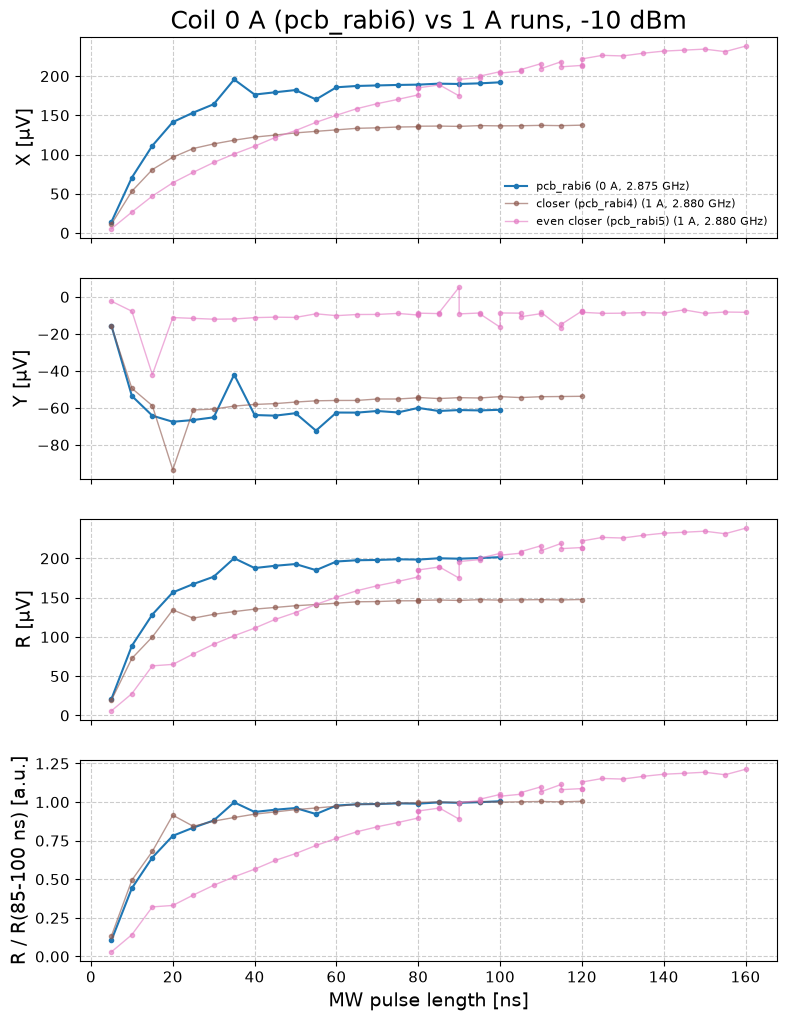

In [8]:
zero = load_rabi("pcb_rabi6_further")
print(f"pcb_rabi6_further: {zero['metadata']['freq_hz']} Hz, {zero['metadata']['drive_power_dbm']} dBm, "
      f"coil {zero['metadata']['coil_current_a']} A, overload points {int(zero['overload'].sum())}")

curves = {"pcb_rabi6 (0 A, 2.875 GHz)": [zero]}
for focus, names in focus_sets.items():
    curves[f"{focus} (1 A, 2.880 GHz)"] = [load_rabi(n) for n in names]

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["r"], ["rnorm"]], sharex=True, figsize=(9, 12))
for i, (label, pieces) in enumerate(curves.items()):
    t = np.concatenate([p["mw_us"] for p in pieces]) * 1e3
    x_uv = np.concatenate([p["x"] for p in pieces]) * 1e6
    y_uv = np.concatenate([p["y"] for p in pieces]) * 1e6
    order = np.argsort(t, kind="stable")
    t, x_uv, y_uv = t[order], x_uv[order], y_uv[order]
    r_uv = np.hypot(x_uv, y_uv)
    ref = r_uv[(t >= 85) & (t <= 100)].mean()
    color = "C0" if i == 0 else f"C{i + 4}"
    for key, v in (("x", x_uv), ("y", y_uv), ("r", r_uv), ("rnorm", r_uv / ref)):
        axs[key].plot(t, v, "o-", ms=3, lw=1.5 if i == 0 else 1, color=color, alpha=1 if i == 0 else 0.6,
                      label=label if key == "x" else None)
    t_half = t[np.argmax(r_uv >= 0.5 * ref)]
    print(f"{label}: R(85-100 ns) {ref:.1f} µV, first reaches half of that at {t_half:.0f} ns")

axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("Coil 0 A (pcb_rabi6) vs 1 A runs, -10 dBm")
axs["x"].legend(fontsize=8)
axs["y"].set_ylabel("Y [µV]")
axs["r"].set_ylabel("R [µV]")
axs["rnorm"].set_ylabel("R / R(85-100 ns) [a.u.]")
axs["rnorm"].set_xlabel("MW pulse length [ns]")
plt.show()

## Detuning, first try: pcb_rabi6_further_detuned (2.877 GHz) vs pcb_rabi6_further (2.875 GHz)

Coil 0 A, -10 dBm, same focus and pulse grid; the drive is moved 2 MHz.

2.875 GHz (pcb_rabi6_further): plateau R (t >= 60 ns) 198.9 µV, half-plateau at 15 ns, CW reflected -11.73 dBm
2.877 GHz (pcb_rabi6_further_detuned): plateau R (t >= 60 ns) 195.5 µV, half-plateau at 15 ns, CW reflected -12.29 dBm


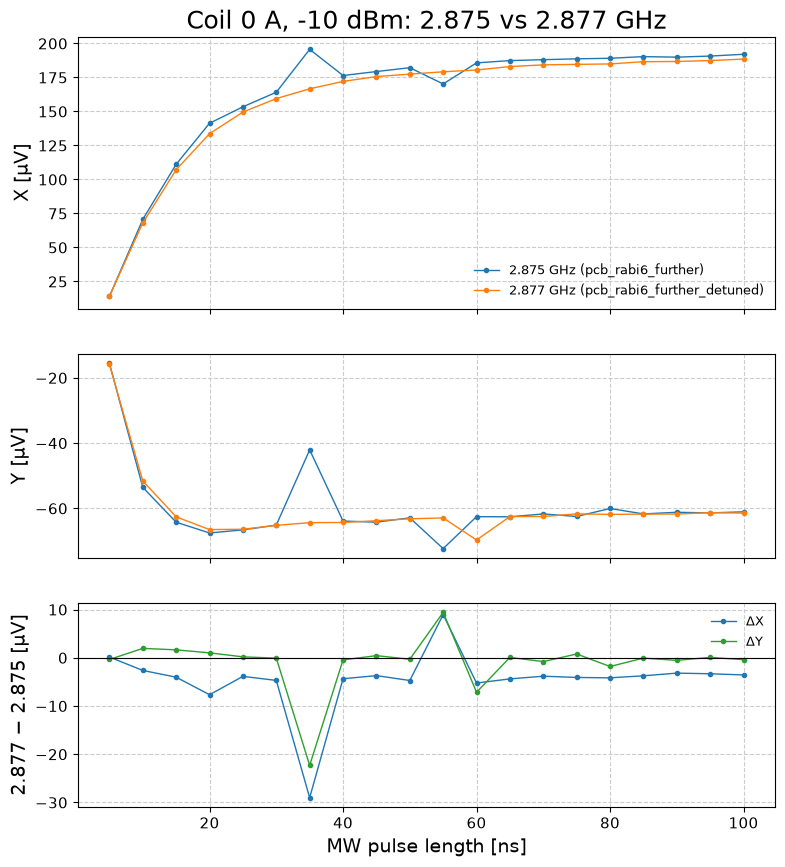

In [9]:
det_runs = {"2.875 GHz (pcb_rabi6_further)": load_rabi("pcb_rabi6_further"),
            "2.877 GHz (pcb_rabi6_further_detuned)": load_rabi("pcb_rabi6_further_detuned")}
(base, det) = det_runs.values()
assert np.allclose(base["mw_us"], det["mw_us"]), "pulse-length grids differ"
t_ns = base["mw_us"] * 1e3
for label, r in det_runs.items():
    r_uv = np.hypot(r["x"], r["y"]) * 1e6
    refl = r["reflected_dbm"][np.isfinite(r["reflected_dbm"])]
    print(f"{label}: plateau R (t >= 60 ns) {r_uv[t_ns >= 60].mean():.1f} µV, "
          f"half-plateau at {t_ns[np.argmax(r_uv >= 0.5 * r_uv[t_ns >= 60].mean())]:.0f} ns, "
          f"CW reflected {refl.mean():.2f} dBm")

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["diff"]], sharex=True, figsize=(9, 10),
                              height_ratios=[2, 1.5, 1.5])
for i, (label, r) in enumerate(det_runs.items()):
    axs["x"].plot(t_ns, r["x"] * 1e6, "o-", ms=3, lw=1, color=f"C{i}", label=label)
    axs["y"].plot(t_ns, r["y"] * 1e6, "o-", ms=3, lw=1, color=f"C{i}")
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("Coil 0 A, -10 dBm: 2.875 vs 2.877 GHz")
axs["x"].legend(fontsize=9)
axs["y"].set_ylabel("Y [µV]")
axs["diff"].plot(t_ns, (det["x"] - base["x"]) * 1e6, "o-", ms=3, lw=1, color="C0", label="ΔX")
axs["diff"].plot(t_ns, (det["y"] - base["y"]) * 1e6, "o-", ms=3, lw=1, color="C2", label="ΔY")
axs["diff"].axhline(0, color="k", lw=0.8)
axs["diff"].set_ylabel("2.877 − 2.875 [µV]")
axs["diff"].set_xlabel("MW pulse length [ns]")
axs["diff"].legend(fontsize=9)
plt.show()

## Detuned +20 MHz: pcb_rabi6_further_detuned_more (2.895 GHz)

Coil 0 A, -10 dBm, 5-60 ns in 2.5 ns steps, same focus as pcb_rabi6. Signal is (X, Y) projected onto its main direction. Fitted with a dephasing Rabi oscillation at the generalized frequency f' = sqrt(f_R² + Δ²); Δ is taken relative to the assumed (unmeasured) line centre 2.875 GHz, so f_R is quoted for Δ ± 3 MHz. Fitted with and without the CW-interlock check points (circled), which have shown glitches before.

C:\Users\codin\AppData\Local\Temp\ipykernel_100164\218827462.py:21: RuntimeWarning: overflow encountered in exp
  return offset + amp * (1 - np.exp(-t / tau) * np.cos(2 * np.pi * f_mhz * 1e-3 * (t - t0)))


all points: f' = 20.0 +/- 1.9 MHz (period 50 ns), decay 9 +/- 0 ns -> f_R = sqrt(f'^2 - Δ^2) = 1.1 MHz (Δ = 20 ± 3 MHz gives 0.0-10.6 MHz)
CW-check points excluded: f' = 20.1 +/- 1.8 MHz (period 50 ns), decay 10 +/- 0 ns -> f_R = sqrt(f'^2 - Δ^2) = 2.1 MHz (Δ = 20 ± 3 MHz gives 0.0-10.7 MHz)
signal direction -30.2 deg; CW checks before points 1, 6, 11, 16, 21 (5.0, 17.0, 30.0, 42.0, 55.0 ns)


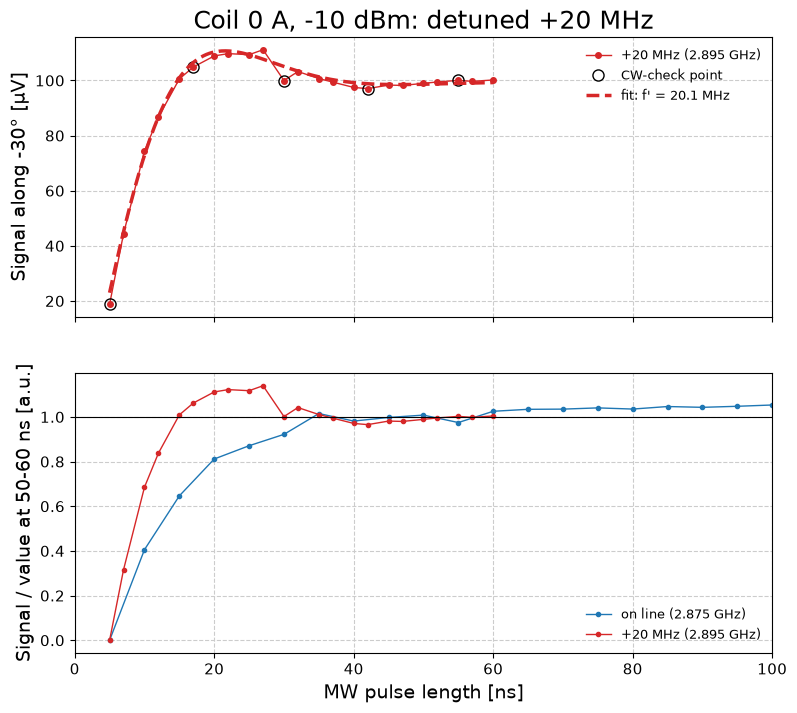

In [10]:
from scipy.optimize import curve_fit

ASSUMED_CENTER_HZ = 2.875e9
det20 = load_rabi("pcb_rabi6_further_detuned_more")
t20 = det20["mw_us"] * 1e3
x20, y20 = det20["x"] * 1e6, det20["y"] * 1e6
axis20, angle20 = principal_axis(det20["x"], det20["y"])
s20 = x20 * axis20[0] + y20 * axis20[1]
if s20[np.argmax(np.abs(s20 - s20[0]))] < s20[0]:
    s20 = -s20
detuning_mhz = (float(det20["metadata"]["freq_hz"]) - ASSUMED_CENTER_HZ) / 1e6

log20 = (RABI_DATA_DIR / "logs" / "pcb_rabi6_further_detuned_more_rabi.txt").read_text()
checked_pts = [int(p) - 1 for p in re.findall(r"CW interlock check \(point (\d+)/", log20)]
near_check = np.zeros(len(t20), bool)
near_check[checked_pts] = True


def detuned_rabi(t, offset, amp, tau, f_mhz, t0):
    """Signal for a detuned, dephasing Rabi oscillation at generalized frequency f_mhz (t in ns)."""
    return offset + amp * (1 - np.exp(-t / tau) * np.cos(2 * np.pi * f_mhz * 1e-3 * (t - t0)))


fits20 = {}
for label, keep in (("all points", np.ones(len(t20), bool)), ("CW-check points excluded", ~near_check)):
    p, cov = curve_fit(detuned_rabi, t20[keep], s20[keep], p0=[s20[0], s20[-1] / 2, 20, 25, 0],
                       maxfev=50000)
    err = np.sqrt(np.diag(cov))
    fits20[label] = p
    f_r = [np.sqrt(max(p[3] ** 2 - d ** 2, 0)) for d in (detuning_mhz - 3, detuning_mhz, detuning_mhz + 3)]
    print(f"{label}: f' = {p[3]:.1f} +/- {err[3]:.1f} MHz (period {1e3 / p[3]:.0f} ns), "
          f"decay {p[2]:.0f} +/- {err[2]:.0f} ns -> f_R = sqrt(f'^2 - Δ^2) = {f_r[1]:.1f} MHz "
          f"(Δ = {detuning_mhz:.0f} ± 3 MHz gives {f_r[2]:.1f}-{f_r[0]:.1f} MHz)")
print(f"signal direction {angle20:.1f} deg; CW checks before points "
      f"{', '.join(str(i + 1) for i in checked_pts)} ({', '.join(f'{v:.1f}' for v in t20[near_check])} ns)")

base = load_rabi("pcb_rabi6_further")
tb = base["mw_us"] * 1e3
sb = base["x"] * 1e6 * axis20[0] + base["y"] * 1e6 * axis20[1]
sb = sb if sb[-1] > sb[0] else -sb

fig, axs = plt.subplot_mosaic([["sig"], ["norm"]], sharex=True, figsize=(9, 8))
axs["sig"].plot(t20, s20, "o-", ms=4, lw=1, color="C3", label=f"{detuning_mhz:+.0f} MHz (2.895 GHz)")
axs["sig"].plot(t20[near_check], s20[near_check], "o", ms=8, mfc="none", color="k", label="CW-check point")
t_fine = np.linspace(t20.min(), t20.max(), 500)
axs["sig"].plot(t_fine, detuned_rabi(t_fine, *fits20["CW-check points excluded"]), "--", color="C3",
                label=f"fit: f' = {fits20['CW-check points excluded'][3]:.1f} MHz")
axs["sig"].set_ylabel(f"Signal along {angle20:.0f}° [µV]")
axs["sig"].set_title("Coil 0 A, -10 dBm: detuned +20 MHz")
axs["sig"].legend(fontsize=9)

for t, s, label, color in ((tb, sb, "on line (2.875 GHz)", "C0"), (t20, s20, "+20 MHz (2.895 GHz)", "C3")):
    late = s[(t >= 50) & (t <= 60)].mean()
    axs["norm"].plot(t, (s - s[0]) / (late - s[0]), "o-", ms=3, lw=1, color=color, label=label)
axs["norm"].axhline(1, color="k", lw=0.8)
axs["norm"].set_ylabel("Signal / value at 50-60 ns [a.u.]")
axs["norm"].set_xlabel("MW pulse length [ns]")
axs["norm"].set_xlim(0, 100)
axs["norm"].legend(fontsize=9)
plt.show()

## Detuned: 2.855 GHz (pcb_rabi6_further_detuned_less), 2.895 GHz (_more), 2.900 GHz (pcb_rabi7_same_position_2900mhz)

Same focus, grid and settings (0 A, -10 dBm, 5-60 ns in 2.5 ns steps). Each run is fitted for its oscillation frequency f' (CW-check points excluded). Where there is an oscillation, the plateau relative to the on-line run (2.875 GHz) is roughly f_R²/f'², which gives f_R and |Δ| -- but only if f_R is the same as on line, which isn't guaranteed: the PCB's match differs a lot between these frequencies.

on line (2.875 GHz): R plateau (45-60 ns) 191.0 µV


pcb_rabi6_further_detuned_less (2855 MHz, CW reflected -10.8 dBm): plateau ratio to on-line 0.86; no oscillation -- smooth rise to a plateau, f' not determined
pcb_rabi6_further_detuned_more (2895 MHz, CW reflected -20.9 dBm): plateau ratio to on-line 0.52; f' = 20.1 +/- 1.8 MHz, decay 10 ns -> if f_R were the same as on line: f_R ≈ 14.5 MHz, |Δ| ≈ 13.9 MHz, line centre ≈ 2881 MHz
pcb_rabi7_same_position_2900mhz (2900 MHz, CW reflected -21.7 dBm): plateau ratio to on-line 0.41; f' = 27.5 +/- 3.1 MHz, decay 12 ns -> if f_R were the same as on line: f_R ≈ 17.7 MHz, |Δ| ≈ 21.1 MHz, line centre ≈ 2879 MHz


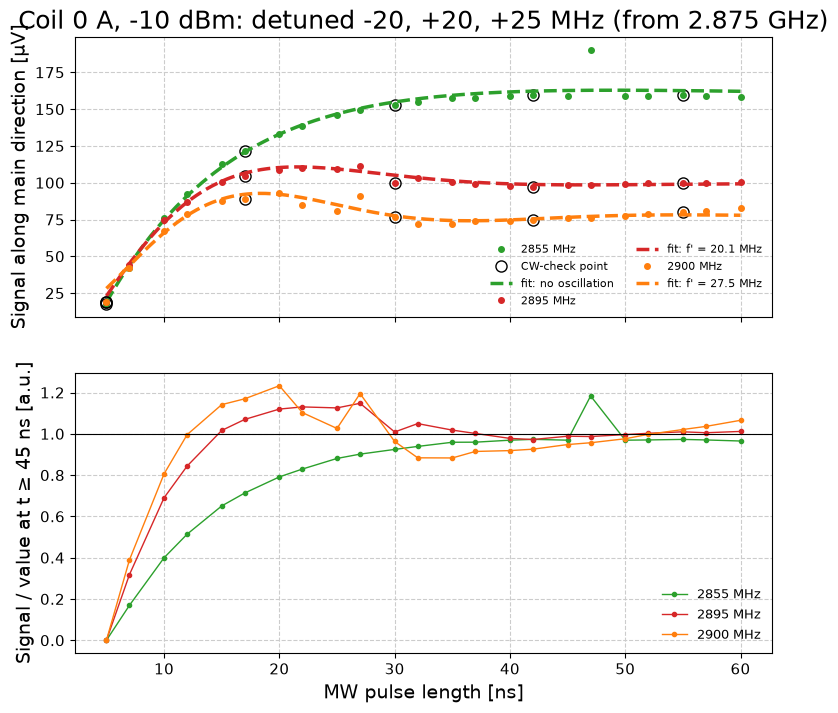

In [11]:
def check_points(name, n):
    log = (RABI_DATA_DIR / "logs" / f"{name}_rabi.txt").read_text()
    mask = np.zeros(n, bool)
    mask[[int(p) - 1 for p in re.findall(r"CW interlock check \(point (\d+)/", log)]] = True
    return mask


def fit_detuned(name):
    """Project onto the run's main X/Y direction (rising sign) and fit detuned_rabi, CW-check points excluded.
    'oscillates' is False when the fit collapses to no oscillation (f' near 0 or unconstrained)."""
    r = load_rabi(name)
    t = r["mw_us"] * 1e3
    axis, angle = principal_axis(r["x"], r["y"])
    s = (r["x"] * axis[0] + r["y"] * axis[1]) * 1e6
    s = s if s[-1] > s[0] else -s
    keep = ~check_points(name, len(t))
    p, cov = curve_fit(detuned_rabi, t[keep], s[keep], p0=[s[0], s[-1] / 2, 10, 20, 0], maxfev=50000)
    err = np.sqrt(np.diag(cov))
    return dict(t=t, s=s, keep=keep, angle=angle, p=p, err=err,
                oscillates=bool(p[3] > 1 and err[3] < p[3]),
                r_plateau=np.hypot(r["x"], r["y"])[(t >= 45) & (t <= 60)].mean() * 1e6,
                freq_mhz=float(r["metadata"]["freq_hz"]) / 1e6,
                refl=np.nanmean(r["reflected_dbm"]))


on_line = load_rabi("pcb_rabi6_further")
t_on = on_line["mw_us"] * 1e3
r_on_plateau = np.hypot(on_line["x"], on_line["y"])[(t_on >= 45) & (t_on <= 60)].mean() * 1e6
print(f"on line (2.875 GHz): R plateau (45-60 ns) {r_on_plateau:.1f} µV")

detuned = {name: fit_detuned(name) for name in ("pcb_rabi6_further_detuned_less",
                                                  "pcb_rabi6_further_detuned_more",
                                                  "pcb_rabi7_same_position_2900mhz")}
for name, d in detuned.items():
    c = d["r_plateau"] / r_on_plateau
    head = (f"{name} ({d['freq_mhz']:.0f} MHz, CW reflected {d['refl']:.1f} dBm): "
            f"plateau ratio to on-line {c:.2f}")
    if not d["oscillates"]:
        print(f"{head}; no oscillation -- smooth rise to a plateau, f' not determined")
        continue
    f_gen, f_err = d["p"][3], d["err"][3]
    f_r, abs_delta = np.sqrt(c) * f_gen, np.sqrt(1 - c) * f_gen
    side = np.sign(d["freq_mhz"] - ASSUMED_CENTER_HZ / 1e6)
    print(f"{head}; f' = {f_gen:.1f} +/- {f_err:.1f} MHz, decay {d['p'][2]:.0f} ns -> if f_R were the same "
          f"as on line: f_R ≈ {f_r:.1f} MHz, |Δ| ≈ {abs_delta:.1f} MHz, line centre ≈ "
          f"{d['freq_mhz'] - side * abs_delta:.0f} MHz")

fig, axs = plt.subplot_mosaic([["sig"], ["norm"]], sharex=True, figsize=(9, 8))
t_fine = np.linspace(5, 60, 500)
for i, (name, d) in enumerate(detuned.items()):
    color = ("C2", "C3", "C1")[i]
    label = f"{d['freq_mhz']:.0f} MHz"
    axs["sig"].plot(d["t"], d["s"], "o", ms=4, color=color, label=label)
    axs["sig"].plot(d["t"][~d["keep"]], d["s"][~d["keep"]], "o", ms=8, mfc="none", color="k",
                    label="CW-check point" if i == 0 else None)
    fit_label = f"fit: f' = {d['p'][3]:.1f} MHz" if d["oscillates"] else "fit: no oscillation"
    axs["sig"].plot(t_fine, detuned_rabi(t_fine, *d["p"]), "--", color=color, label=fit_label)
    late = d["s"][(d["t"] >= 45)].mean()
    axs["norm"].plot(d["t"], (d["s"] - d["s"][0]) / (late - d["s"][0]), "o-", ms=3, lw=1, color=color,
                     label=label)
axs["sig"].set_ylabel("Signal along main direction [µV]")
axs["sig"].set_title("Coil 0 A, -10 dBm: detuned -20, +20, +25 MHz (from 2.875 GHz)")
axs["sig"].legend(fontsize=8, ncol=2)
axs["norm"].axhline(1, color="k", lw=0.8)
axs["norm"].set_ylabel("Signal / value at t ≥ 45 ns [a.u.]")
axs["norm"].set_xlabel("MW pulse length [ns]")
axs["norm"].legend(fontsize=9)
plt.show()

## Off-resonance control and detunings about the measured centre

Line centre from the zero-field CW scan `pcb_rabi_focus6` (pcb_test.ipynb): 2870.1 MHz, two-line fit 2864.5 / 2875.7 MHz. All runs at 0 A, -10 dBm, same focus, 2.5 ns steps.

- **2.450 GHz** (pcb_rabi7_same_position_2450mhz, stopped after 18 points): far from any NV line, so any signal is not spin.
- **2.845 GHz** (-25 MHz) vs **2.895 GHz** (+25 MHz): mirror images about the centre; **2.900 GHz repeat** (+30 MHz) for comparison.

pcb_rabi7_same_position_2450mhz: 18 points; off-check X = +0.02 ± 0.23 µV, Y = +0.03 ± 0.22 µV; at CW-check points: 5.0 ns X +0.3 Y -0.5, 30.0 ns X -11.9 Y +23.2
pcb_rabi7_same_position_2845mhz_test: 2845 MHz (-25 from centre, -19.5 from line 2864.5), CW reflected -12.5 dBm, plateau R 103 µV, f' = 22.9 +/- 1.8 MHz, decay 9.3 ns
pcb_rabi6_further_detuned_more: 2895 MHz (+25 from centre, +19.3 from line 2875.7), CW reflected -20.9 dBm, plateau R 100 µV, f' = 20.1 +/- 1.8 MHz, decay 9.6 ns
pcb_rabi7_same_position_2900mhz_repeat: 2900 MHz (+30 from centre, +24.3 from line 2875.7), CW reflected -21.4 dBm, plateau R 81 µV, f' = 30.9 +/- 2.7 MHz, decay 10.1 ns


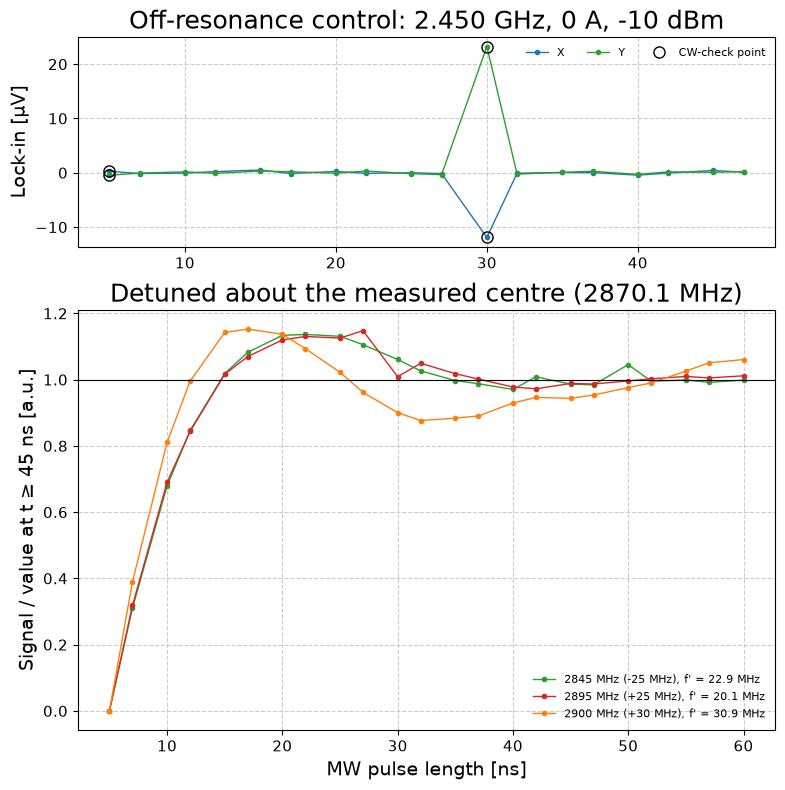

In [12]:
LINE_CENTER_MHZ = 2870.1           # pcb_rabi_focus6 one-line fit
LINES_MHZ = (2864.5, 2875.7)       # pcb_rabi_focus6 two-line fit

# Off-resonance control (stopped by hand after 18 points)
ctrl_name = "pcb_rabi7_same_position_2450mhz"
ctrl = load_rabi(ctrl_name)
t_c = ctrl["mw_us"] * 1e3
x_c, y_c = ctrl["x"] * 1e6, ctrl["y"] * 1e6
chk_c = check_points(ctrl_name, len(t_c))
print(f"{ctrl_name}: {len(t_c)} points; off-check X = {x_c[~chk_c].mean():+.2f} ± {x_c[~chk_c].std():.2f} µV, "
      f"Y = {y_c[~chk_c].mean():+.2f} ± {y_c[~chk_c].std():.2f} µV; at CW-check points: "
      + ", ".join(f"{t:.1f} ns X {x:+.1f} Y {y:+.1f}" for t, x, y in zip(t_c[chk_c], x_c[chk_c], y_c[chk_c])))

# Mirror pair about the measured centre, plus the +30 MHz repeat
pair_names = ("pcb_rabi7_same_position_2845mhz_test", "pcb_rabi6_further_detuned_more",
              "pcb_rabi7_same_position_2900mhz_repeat")
pair = {name: fit_detuned(name) for name in pair_names}
for name, d in pair.items():
    nearest = min(LINES_MHZ, key=lambda c: abs(d["freq_mhz"] - c))
    print(f"{name}: {d['freq_mhz']:.0f} MHz ({d['freq_mhz'] - LINE_CENTER_MHZ:+.0f} from centre, "
          f"{d['freq_mhz'] - nearest:+.1f} from line {nearest}), CW reflected {d['refl']:.1f} dBm, "
          f"plateau R {d['r_plateau']:.0f} µV, f' = {d['p'][3]:.1f} +/- {d['err'][3]:.1f} MHz, "
          f"decay {d['p'][2]:.1f} ns")

fig, axs = plt.subplot_mosaic([["ctrl"], ["pair"]], figsize=(9, 9), height_ratios=[1, 2])
axs["ctrl"].plot(t_c, x_c, "o-", ms=3, lw=1, color="C0", label="X")
axs["ctrl"].plot(t_c, y_c, "o-", ms=3, lw=1, color="C2", label="Y")
axs["ctrl"].plot(t_c[chk_c], x_c[chk_c], "o", ms=8, mfc="none", color="k", label="CW-check point")
axs["ctrl"].plot(t_c[chk_c], y_c[chk_c], "o", ms=8, mfc="none", color="k")
axs["ctrl"].set_ylabel("Lock-in [µV]")
axs["ctrl"].set_title("Off-resonance control: 2.450 GHz, 0 A, -10 dBm")
axs["ctrl"].legend(fontsize=8, ncol=3)

for i, (name, d) in enumerate(pair.items()):
    late = d["s"][d["t"] >= 45].mean()
    color = ("C2", "C3", "C1")[i]
    axs["pair"].plot(d["t"], (d["s"] - d["s"][0]) / (late - d["s"][0]), "o-", ms=3, lw=1, color=color,
                     label=f"{d['freq_mhz']:.0f} MHz ({d['freq_mhz'] - LINE_CENTER_MHZ:+.0f} MHz), "
                           f"f' = {d['p'][3]:.1f} MHz")
axs["pair"].axhline(1, color="k", lw=0.8)
axs["pair"].set_ylabel("Signal / value at t ≥ 45 ns [a.u.]")
axs["pair"].set_xlabel("MW pulse length [ns]")
axs["pair"].set_title("Detuned about the measured centre (2870.1 MHz)")
axs["pair"].legend(fontsize=8)
plt.show()

## Coil 3 A: pcb_rabi7_same_position_static_on (2.920 GHz, -10 dBm)

Same focus as the pcb_rabi7 runs. At 3 A the upper transitions are at 2895.6 / 2905.7 MHz (`pcb_rabi_focus6_more_redo`, pcb_test.ipynb), so 2.920 GHz is +14.3 MHz from the nearer line and +24.4 MHz from the other. Compared with the 0 A run at 2.900 GHz (+24.3 MHz from 2875.7).

Here the glitches (off the main X/Y direction) are at points 7, 15 and 18, not at the CW-check points (1, 11, 21). They're left out of the fit and shown as crosses.

C:\Users\codin\AppData\Local\Temp\ipykernel_100164\1689241568.py:20: OptimizeWarning: Covariance of the parameters could not be estimated
  p_try, cov_try = curve_fit(detuned_rabi, t[keep], s[keep], p0=[s[0], (s[-1] - s[0]) / 2, 15, f0, 0],


3 A, 2920 MHz: rise 87 µV, overshoot 4.4 µV, f' = 19.6 +/- 1.3 MHz, decay 8.4 +/- 0.7 ns, rms 1.3 µV; Δ to nearest line +14.3 MHz -> f_R ≈ 13 MHz
0 A, 2900 MHz: rise 63 µV, overshoot 8.2 µV, f' = 30.2 +/- 2.7 MHz, decay 8.9 +/- 0.7 ns, rms 2.4 µV; Δ to nearest line +24.3 MHz -> f_R ≈ 18 MHz


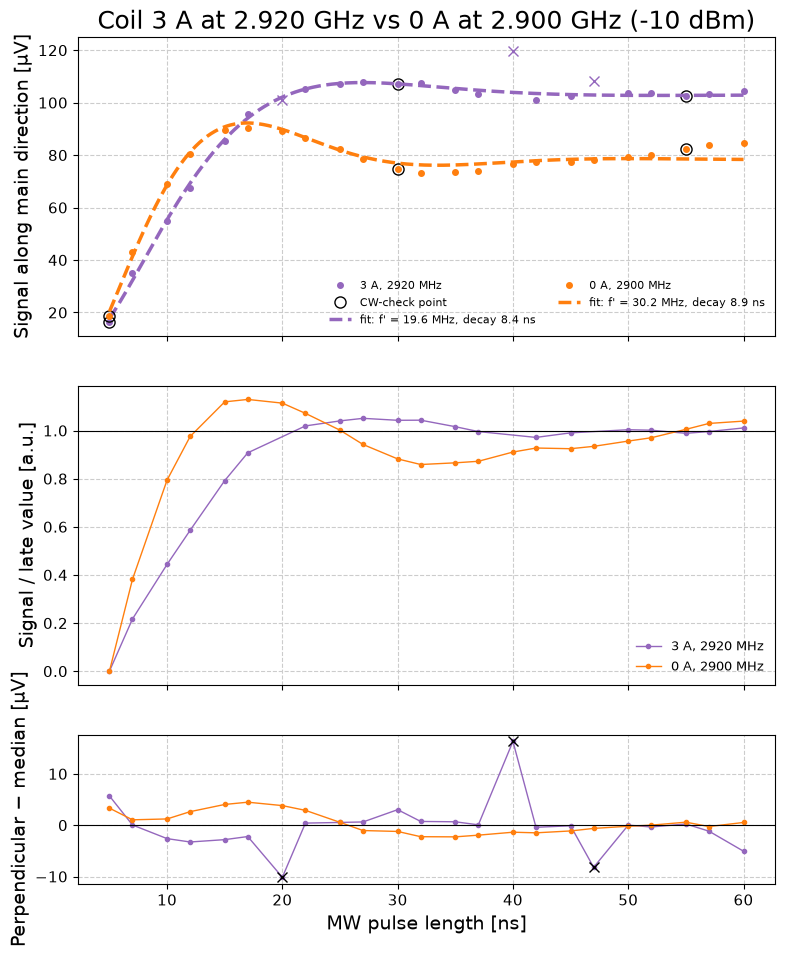

In [13]:
LINES_3A_MHZ = (2895.6, 2905.7)    # pcb_rabi_focus6_more_redo, upper transitions at 3 A


def fit_projected(name, skip_points=()):
    """Like fit_detuned, but leaves out the given 1-based points instead of the CW-check points.
    Also returns the component perpendicular to the main direction (where glitches show)."""
    r = load_rabi(name)
    t = r["mw_us"] * 1e3
    axis, angle = principal_axis(r["x"], r["y"])
    s = (r["x"] * axis[0] + r["y"] * axis[1]) * 1e6
    sign = 1 if s[-1] > s[0] else -1
    s = sign * s
    perp = (-r["x"] * axis[1] + r["y"] * axis[0]) * 1e6
    keep = np.ones(len(t), bool)
    keep[[p - 1 for p in skip_points]] = False
    # Several starting frequencies, keep the lowest residual (a single start can land in a bad local minimum)
    best = None
    for f0 in (15, 20, 25, 30):
        try:
            p_try, cov_try = curve_fit(detuned_rabi, t[keep], s[keep], p0=[s[0], (s[-1] - s[0]) / 2, 15, f0, 0],
                                       maxfev=50000)
        except RuntimeError:
            continue
        rss = np.sum((s[keep] - detuned_rabi(t[keep], *p_try)) ** 2)
        if np.all(np.isfinite(np.diag(cov_try))) and (best is None or rss < best[0]):
            best = (rss, p_try, cov_try)
    _, p, cov = best
    p[3] = abs(p[3])  # sign of f' is arbitrary
    late = s[keep][-5:].mean()
    return dict(t=t, s=s, perp=perp, keep=keep, check=check_points(name, len(t)), p=p,
                err=np.sqrt(np.diag(cov)), rise=late - s[0], overshoot=s[keep].max() - late,
                rms=np.sqrt(np.mean((s[keep] - detuned_rabi(t[keep], *p)) ** 2)),
                freq_mhz=float(r["metadata"]["freq_hz"]) / 1e6, coil_a=float(r["metadata"]["coil_current_a"]))


coil_runs = {"3 A, 2920 MHz": fit_projected("pcb_rabi7_same_position_static_on", skip_points=(7, 15, 18)),
             "0 A, 2900 MHz": fit_projected("pcb_rabi7_same_position_2900mhz_repeat")}
for label, d in coil_runs.items():
    lines = LINES_3A_MHZ if d["coil_a"] > 0 else LINES_MHZ
    delta = d["freq_mhz"] - min(lines, key=lambda c: abs(d["freq_mhz"] - c))
    f_r = np.sqrt(max(d["p"][3] ** 2 - delta ** 2, 0))
    print(f"{label}: rise {d['rise']:.0f} µV, overshoot {d['overshoot']:.1f} µV, "
          f"f' = {d['p'][3]:.1f} +/- {d['err'][3]:.1f} MHz, decay {d['p'][2]:.1f} +/- {d['err'][2]:.1f} ns, "
          f"rms {d['rms']:.1f} µV; Δ to nearest line {delta:+.1f} MHz -> f_R ≈ {f_r:.0f} MHz")

fig, axs = plt.subplot_mosaic([["sig"], ["norm"], ["perp"]], sharex=True, figsize=(9, 11),
                              height_ratios=[2, 2, 1])
t_fine = np.linspace(5, 60, 500)
for i, (label, d) in enumerate(coil_runs.items()):
    color = ("C4", "C1")[i]
    k, out = d["keep"], ~d["keep"]
    axs["sig"].plot(d["t"][k], d["s"][k], "o", ms=4, color=color, label=label)
    axs["sig"].plot(d["t"][out], d["s"][out], "x", ms=7, color=color)
    axs["sig"].plot(d["t"][d["check"]], d["s"][d["check"]], "o", ms=8, mfc="none", color="k",
                    label="CW-check point" if i == 0 else None)
    axs["sig"].plot(t_fine, detuned_rabi(t_fine, *d["p"]), "--", color=color,
                    label=f"fit: f' = {d['p'][3]:.1f} MHz, decay {d['p'][2]:.1f} ns")
    norm = (d["s"] - d["s"][0]) / d["rise"]
    axs["norm"].plot(d["t"][k], norm[k], "o-", ms=3, lw=1, color=color, label=label)
    axs["perp"].plot(d["t"], d["perp"] - np.median(d["perp"]), "o-", ms=3, lw=1, color=color, label=label)
    axs["perp"].plot(d["t"][out], (d["perp"] - np.median(d["perp"]))[out], "x", ms=7, color="k")
axs["sig"].set_ylabel("Signal along main direction [µV]")
axs["sig"].set_title("Coil 3 A at 2.920 GHz vs 0 A at 2.900 GHz (-10 dBm)")
axs["sig"].legend(fontsize=8, ncol=2)
axs["norm"].axhline(1, color="k", lw=0.8)
axs["norm"].set_ylabel("Signal / late value [a.u.]")
axs["norm"].legend(fontsize=9)
axs["perp"].axhline(0, color="k", lw=0.8)
axs["perp"].set_ylabel("Perpendicular − median [µV]")
axs["perp"].set_xlabel("MW pulse length [ns]")
plt.show()

## Coil 0 A: all drive frequencies overlaid

Every 0 A, -10 dBm run with at least 10 points, found by scanning `D:\rabi` (2.450 GHz controls left out). Signal is (X, Y) along each run's own main direction; f' from `detuned_rabi` (CW-check points excluded) is only quoted more than 10 MHz from the centre, since near the line there's no fringe and the fit isn't meaningful. The `_cont` piece (60-120 ns) is projected on its first part's direction and shown in the top panel only.

pcb_rabi7_same_position_2845mhz_test: 2845 MHz, 5-60 ns, plateau (45-60 ns) 102 µV
pcb_rabi6_further_detuned_less: 2855 MHz, 5-60 ns, plateau (45-60 ns) 164 µV
pcb_rabi6_further: 2875 MHz, 5-100 ns, plateau (45-60 ns) 188 µV


pcb_rabi6_further_detuned: 2877 MHz, 5-100 ns, plateau (45-60 ns) 187 µV
pcb_rabi6_further_detuned_more: 2895 MHz, 5-60 ns, plateau (45-60 ns) 99 µV
pcb_rabi7_same_position_2900mhz: 2900 MHz, 5-60 ns, plateau (45-60 ns) 79 µV
pcb_rabi7_same_position_2900mhz_cont: 2900 MHz, 60-120 ns (continuation, top panel only)
pcb_rabi7_same_position_2900mhz_repeat: 2900 MHz, 5-60 ns, plateau (45-60 ns) 81 µV


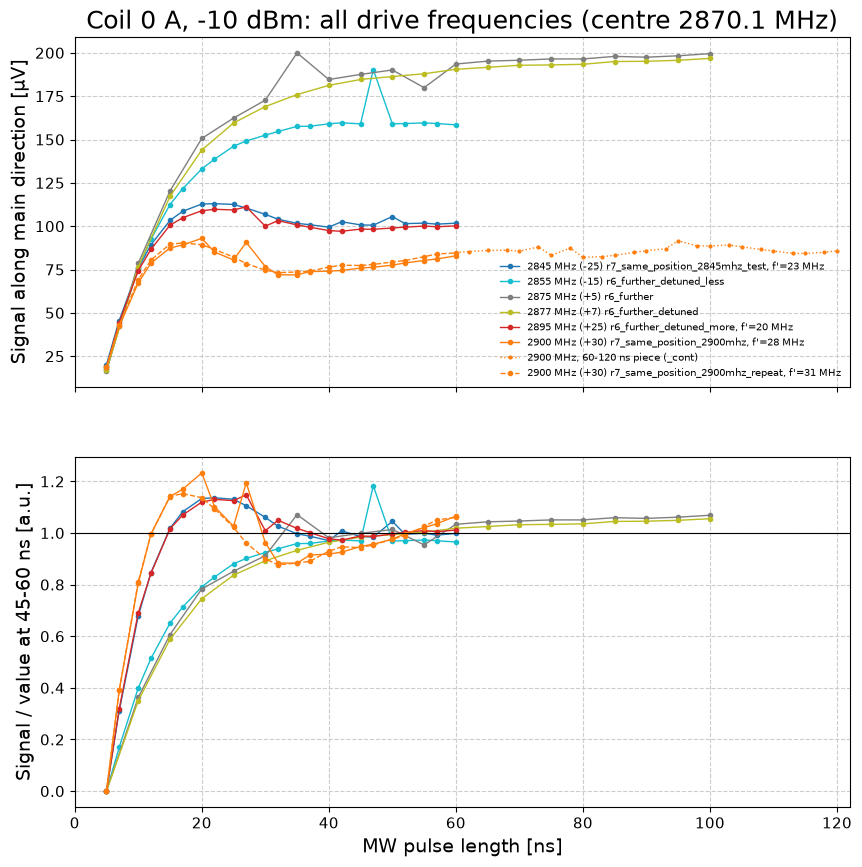

In [14]:
ZERO_A_COLORS = {2845: "C0", 2855: "C9", 2875: "C7", 2877: "C8", 2895: "C3", 2900: "C1"}


def projected(r, axis=None, sign=None):
    """(X, Y) in µV along axis (default: the run's own main direction), with sign chosen so it rises
    unless given. Returns (signal, axis, sign)."""
    if axis is None:
        axis, _ = principal_axis(r["x"], r["y"])
    s = (r["x"] * axis[0] + r["y"] * axis[1]) * 1e6
    if sign is None:
        sign = 1 if s[-1] > s[0] else -1
    return sign * s, axis, sign


zero_a = {}
for d in sorted(RABI_DATA_DIR.glob("pcb_rabi*")):
    if not (d / f"{d.name}_rabi_metadata.txt").exists():
        continue  # e.g. run-repeat folders, whose files are prefixed _repeat{i}
    r = load_rabi(d.name)
    f_mhz = float(r["metadata"]["freq_hz"]) / 1e6
    if (float(r["metadata"]["coil_current_a"]) == 0 and float(r["metadata"]["drive_power_dbm"]) == -10
            and len(r["mw_us"]) >= 10 and f_mhz > 2800):
        zero_a[d.name] = r
zero_a = dict(sorted(zero_a.items(), key=lambda kv: float(kv[1]["metadata"]["freq_hz"])))

fig, axs = plt.subplot_mosaic([["raw"], ["norm"]], sharex=True, figsize=(10, 10))
for name, r in zero_a.items():
    t = r["mw_us"] * 1e3
    f_mhz = float(r["metadata"]["freq_hz"]) / 1e6
    color = ZERO_A_COLORS.get(round(f_mhz), "k")
    if t.min() >= 60:  # continuation piece: project on its first part's direction and sign
        _, axis_first, sign_first = projected(load_rabi(name.replace("_cont", "")))
        s, _, _ = projected(r, axis_first, sign_first)
        axs["raw"].plot(t, s, "o:", ms=2, lw=1, color=color, label=f"{f_mhz:.0f} MHz, 60-120 ns piece (_cont)")
        print(f"{name}: {f_mhz:.0f} MHz, {t.min():.0f}-{t.max():.0f} ns (continuation, top panel only)")
        continue

    s, _, _ = projected(r)
    label = f"{f_mhz:.0f} MHz ({f_mhz - LINE_CENTER_MHZ:+.0f}) {name.replace('pcb_rabi', 'r')}"
    keep = ~check_points(name, len(t)) & (t <= 60)
    try:
        p, _ = curve_fit(detuned_rabi, t[keep], s[keep], p0=[s[0], s[-1] / 2, 10, 20, 0], maxfev=50000)
        if abs(p[3]) > 1 and abs(f_mhz - LINE_CENTER_MHZ) > 10:
            label += f", f'={abs(p[3]):.0f} MHz"
    except RuntimeError:
        pass  # no convergence (smooth rise with no fringe) -- just leave f' off the label
    late = s[(t >= 45) & (t <= 60)].mean()
    print(f"{name}: {f_mhz:.0f} MHz, {t.min():.0f}-{t.max():.0f} ns, plateau (45-60 ns) {late:.0f} µV")
    style = "--" if "repeat" in name else "-"
    axs["raw"].plot(t, s, "o" + style, ms=3, lw=1, color=color, label=label)
    axs["norm"].plot(t, (s - s[0]) / (late - s[0]), "o" + style, ms=3, lw=1, color=color)

axs["raw"].set_ylabel("Signal along main direction [µV]")
axs["raw"].set_title(f"Coil 0 A, -10 dBm: all drive frequencies (centre {LINE_CENTER_MHZ} MHz)")
axs["raw"].legend(fontsize=7, loc="lower right")
axs["norm"].axhline(1, color="k", lw=0.8)
axs["norm"].set_ylabel("Signal / value at 45-60 ns [a.u.]")
axs["norm"].set_xlabel("MW pulse length [ns]")
axs["norm"].set_xlim(0, 122)
plt.show()

## Lock-in trace after each upload: pcb_rabi7_same_position_2450mhz_test_more

2.450 GHz control, 0 A, -10 dBm, run with `cw_check_trace_s=5`: at each CW-check point (1, 6, 11, 16, 21) and the point after, the lock-in was sampled every 0.2 s for 5 s from the sequence restart (`_rabi_cw_trace.npy`). This is the rerun under the same name (the first attempt lost the 480 Hz reference from point 2 on; its files are backed up in the session scratchpad).

- **Glitches follow the AWG reset, not the CW check.** The AWG is reset every `resequence_interval=4` points (before points 5, 9, 13, 17, 21). The point *after* each reset, plus point 2, reads the reference as 480.881 Hz instead of 480.776 Hz -- and those are where the large readings are (points 2, 6, 10, 22; 14 and 18 read 480.881 but were clean). CW-check points 11, 16, 21 are clean.
- **Every upload** gives a 50-130 µV transient that is gone by ~1.6 s after the sequence restart.
- **At the 480.881 Hz points** the disturbance comes back every ~2.1-2.4 s -- about one 1000-rep anchor block (2.08 s), i.e. each time the sequence wraps through its trigger-wait anchor. Normal points show at most ~2 µV there.

point  tau_mw [ns]   R [µV]   SR830 reference [Hz]  notes
    1          5.0     0.40               480.776  CW check
    2          7.0    56.33               480.881  
    3         10.0     0.40               480.776  
    4         12.0     0.49               480.776  
    5         15.0     0.30               480.776  AWG reset
    6         17.0    23.42               480.881  CW check, after reset
    7         20.0     0.93               480.776  
    8         22.0     0.45               480.776  
    9         25.0     0.15               480.776  AWG reset
   10         27.0    23.58               480.881  after reset
   11         30.0     0.75               480.776  CW check
   12         32.0     0.56               480.776  
   13         35.0     0.34               480.776  AWG reset
   14         37.0     0.63               480.881  after reset
   15         40.0     7.86               480.776  
   16         42.0     0.77               480.776  CW check
   17         45

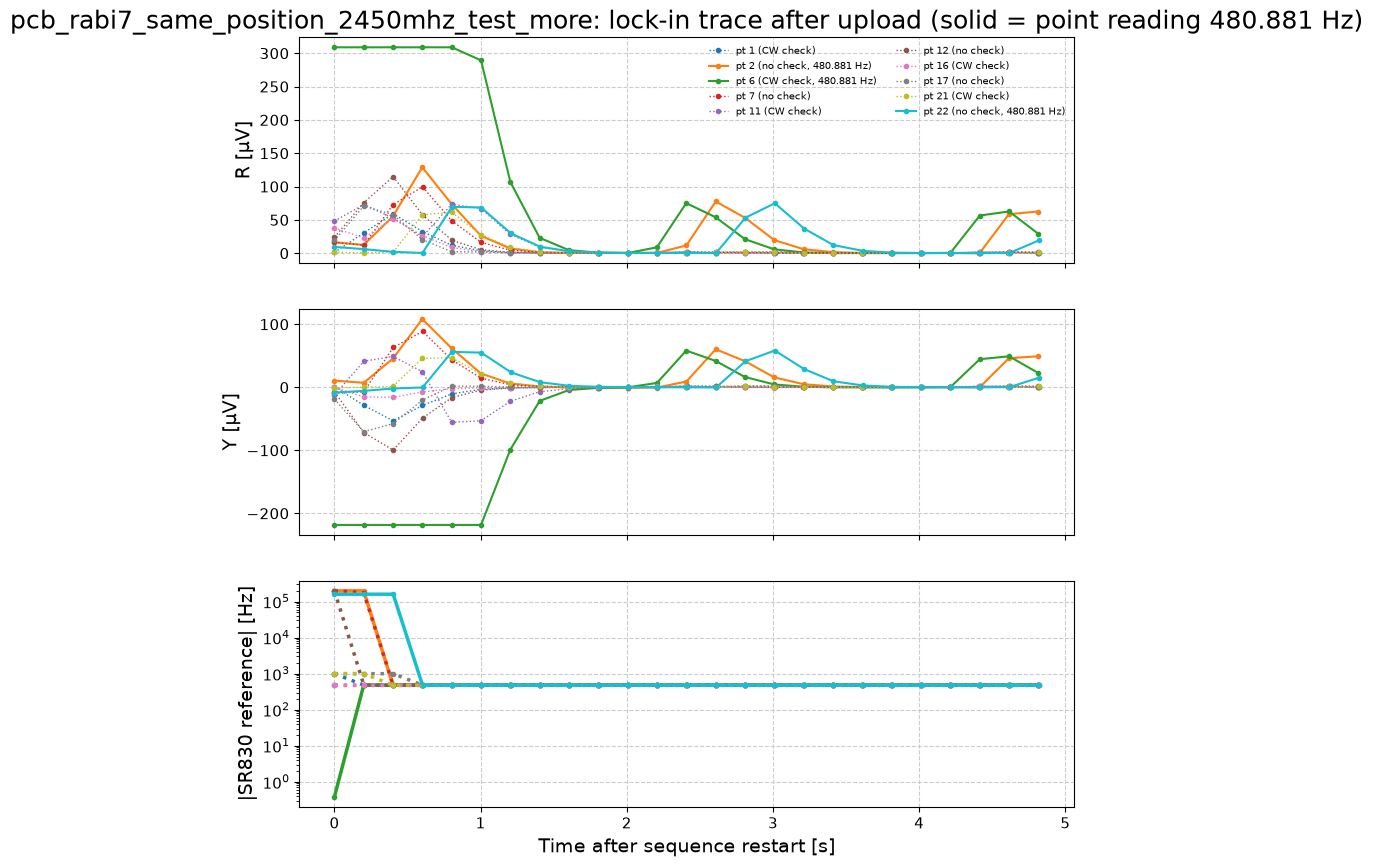

In [15]:
trace_name = "pcb_rabi7_same_position_2450mhz_test_more"
trace_run = load_rabi(trace_name)
# columns: point (1-based), CW check at that point (0/1), t [s] from sequence restart,
# X [V], Y [V], SR830 reference [Hz], reference_unlock, any overload
trace = np.load(RABI_DATA_DIR / trace_name / f"{trace_name}_rabi_cw_trace.npy")
trace_log = (RABI_DATA_DIR / "logs" / f"{trace_name}_rabi.txt").read_text()
reset_pts = {int(p) for p in re.findall(r"point (\d+)/\d+: resetting AWG", trace_log)}

t_mw = trace_run["mw_us"] * 1e3
r_uv = np.hypot(trace_run["x"], trace_run["y"]) * 1e6
chk_mask = check_points(trace_name, len(t_mw))
high_ref = trace_run["ref_freq_hz"] > 480.8
print("point  tau_mw [ns]   R [µV]   SR830 reference [Hz]  notes")
for i in range(len(t_mw)):
    p = i + 1
    notes = [n for n, on in (("CW check", chk_mask[i]), ("AWG reset", p in reset_pts),
                             ("after reset", p - 1 in reset_pts)) if on]
    print(f"{p:5d}  {t_mw[i]:11.1f}  {r_uv[i]:7.2f}  {trace_run['ref_freq_hz'][i]:20.3f}  {', '.join(notes)}")
print(f"\nreference 480.881 Hz: points {list(np.flatnonzero(high_ref) + 1)}, R = {np.round(r_uv[high_ref], 1)} µV")
print(f"reference 480.776 Hz: {int((~high_ref).sum())} points, R mean {r_uv[~high_ref].mean():.2f} µV, "
      f"max {r_uv[~high_ref].max():.1f} µV")

fig, axs = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
for pt in np.unique(trace[:, 0]).astype(int):
    rows = trace[trace[:, 0] == pt]
    after_check = rows[0, 1] == 1
    bad_ref = high_ref[pt - 1]
    label = (f"pt {pt} ({'CW check' if after_check else 'no check'}"
             f"{', 480.881 Hz' if bad_ref else ''})")
    xs, ys = rows[:, 3] * 1e6, rows[:, 4] * 1e6
    style = "-" if bad_ref else ":"
    axs[0].plot(rows[:, 2], np.hypot(xs, ys), style, marker="o", ms=3, lw=1.5 if bad_ref else 1, label=label)
    axs[1].plot(rows[:, 2], ys, style, marker="o", ms=3, lw=1.5 if bad_ref else 1)
    axs[2].plot(rows[:, 2], np.abs(rows[:, 5]), style, marker="o", ms=3)
axs[0].set_ylabel("R [µV]")
axs[1].set_ylabel("Y [µV]")
axs[2].set_ylabel("|SR830 reference| [Hz]")
axs[2].set_yscale("log")
axs[2].set_xlabel("Time after sequence restart [s]")
axs[0].legend(fontsize=7, ncol=2)
axs[0].set_title(f"{trace_name}: lock-in trace after upload (solid = point reading 480.881 Hz)")
plt.show()

## 2.900 GHz repeats: pcb_rabi7_same_position_2900mhz_avg

`rabi.py run-repeat` at the same settings as `pcb_rabi7_same_position_2900mhz` (0 A, -10 dBm, 5-60 ns in 2.5 ns steps). All repeats are projected on one common direction (from their mean). Squares mark points whose reference read 480.881 Hz -- the point after each AWG reset, where glitches have been showing up (see the trace section above). The median is less sensitive to a single glitched repeat than the mean that `run-repeat` saves. Middle panel compares the median's shape with the two earlier single runs.

pcb_rabi7_same_position_2900mhz_avg: 3 repeats, 23 points, signal direction -37.0 deg
point  t[ns]  rep0  rep1  rep2   mean  median  spread  480.881 Hz in
    1    5.0   21.2   20.0   18.6   19.9    20.0     2.6  
    2    7.0   48.3   45.6   67.8   53.9    48.3    22.3  [0, 1, 2]
    3   10.0   77.5   76.3   72.2   75.4    76.3     5.3  
    4   12.0   89.0   85.3   83.7   86.0    85.3     5.3  
    5   15.0   98.1   94.5   93.8   95.5    94.5     4.2  
    6   17.0   99.1   96.7   95.2   97.0    96.7     3.9  [0, 1, 2]
    7   20.0   98.1   94.7   93.9   95.6    94.7     4.2  
    8   22.0   98.1   92.1   90.9   93.7    92.1     7.2  
    9   25.0   89.2   86.8   87.0   87.7    87.0     2.4  
   10   27.0   85.5   83.6   82.7   84.0    83.6     2.8  [0, 1, 2]
   11   30.0   81.4   79.1   78.5   79.7    79.1     2.9  
   12   32.0   80.0   77.9   77.2   78.4    77.9     2.9  
   13   35.0   78.5   77.2   75.7   77.1    77.2     2.8  
   14   37.0   80.3   78.5   77.4   78.7    78.5   

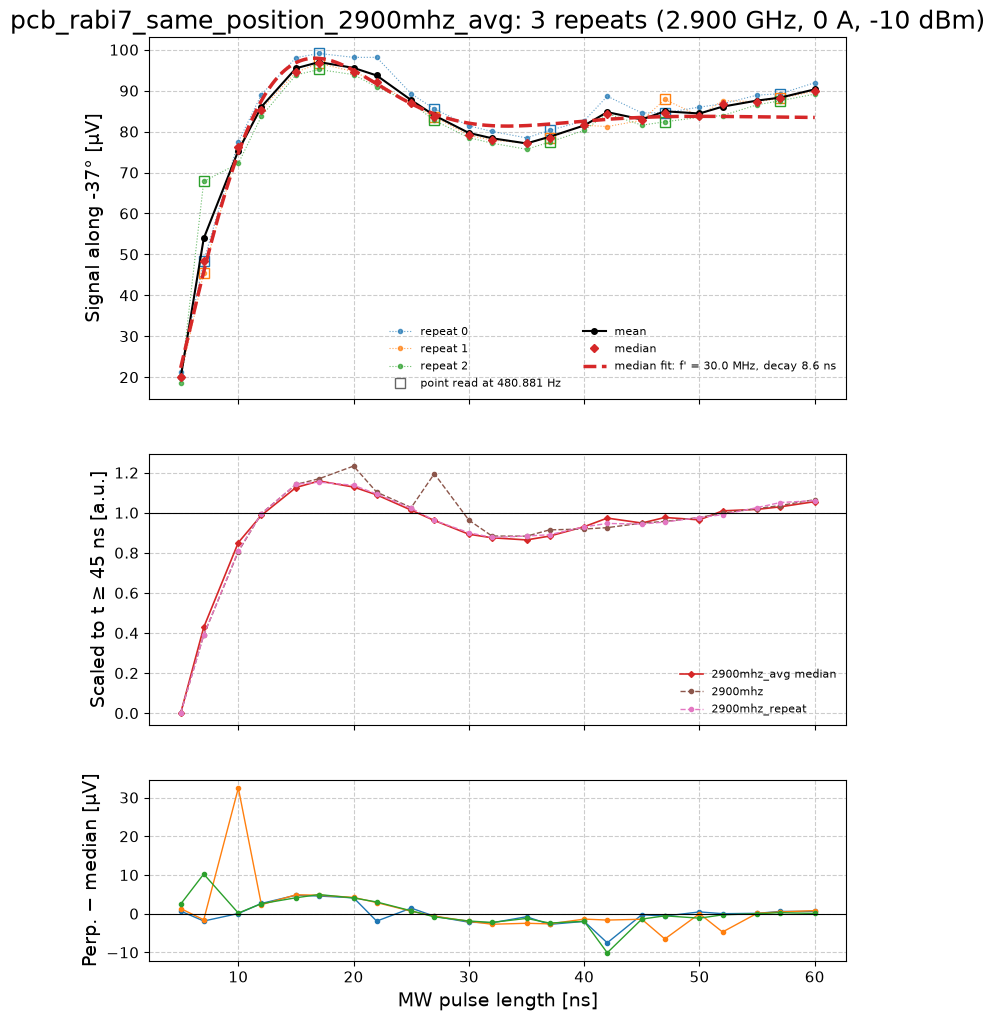

In [16]:
avg_name = "pcb_rabi7_same_position_2900mhz_avg"
avg_dir = RABI_DATA_DIR / avg_name
n_rep = len(list(avg_dir.glob(f"{avg_name}_repeat*_rabi_x.npy")))
reps = []
for k in range(n_rep):
    prefix = avg_dir / f"{avg_name}_repeat{k}_rabi"
    reps.append({key: np.load(f"{prefix}_{key}.npy") for key in ("mw_us", "x", "y", "ref_freq_hz", "reflected_dbm")})
t_avg = played_us(reps[0]["mw_us"]) * 1e3
assert all(np.allclose(played_us(r["mw_us"]) * 1e3, t_avg) for r in reps), "repeat grids differ"
x_all = np.stack([r["x"] for r in reps]) * 1e6
y_all = np.stack([r["y"] for r in reps]) * 1e6

# One common direction for all repeats (from the mean), sign chosen to rise
axis_avg, angle_avg = principal_axis(x_all.mean(0), y_all.mean(0))
s_all = x_all * axis_avg[0] + y_all * axis_avg[1]
sign_avg = 1 if s_all.mean(0)[-1] > s_all.mean(0)[0] else -1
s_all *= sign_avg
perp_all = -x_all * axis_avg[1] + y_all * axis_avg[0]
s_mean, s_median = s_all.mean(0), np.median(s_all, 0)
high_ref_all = np.stack([r["ref_freq_hz"] > 480.8 for r in reps])

print(f"{avg_name}: {n_rep} repeats, {len(t_avg)} points, signal direction {angle_avg:.1f} deg")
print("point  t[ns]  " + "  ".join(f"rep{k}" for k in range(n_rep)) + "   mean  median  spread  480.881 Hz in")
for i in range(len(t_avg)):
    spread = s_all[:, i].max() - s_all[:, i].min()
    hi = [k for k in range(n_rep) if high_ref_all[k, i]]
    print(f"{i + 1:5d}  {t_avg[i]:5.1f}  " + "  ".join(f"{v:5.1f}" for v in s_all[:, i])
          + f"  {s_mean[i]:5.1f}  {s_median[i]:6.1f}  {spread:6.1f}  {hi if hi else ''}")

# Fits: each repeat, the mean, the median
fits_avg = {}
for label, s in [(f"repeat {k}", s_all[k]) for k in range(n_rep)] + [("mean", s_mean), ("median", s_median)]:
    try:
        p, cov = curve_fit(detuned_rabi, t_avg, s, p0=[s[0], s[-1] / 2, 10, 30, 0], maxfev=50000)
        p[3] = abs(p[3])
        fits_avg[label] = (p, np.sqrt(np.diag(cov)), np.sqrt(np.mean((s - detuned_rabi(t_avg, *p)) ** 2)))
        print(f"{label}: f' = {p[3]:.1f} +/- {fits_avg[label][1][3]:.1f} MHz, decay {p[2]:.1f} ns, "
              f"rms {fits_avg[label][2]:.2f} µV")
    except RuntimeError:
        print(f"{label}: fit did not converge")

# Earlier single runs at the same settings, for comparison (projected on their own direction)
earlier = {n: projected(load_rabi(n))[0] for n in ("pcb_rabi7_same_position_2900mhz",
                                                     "pcb_rabi7_same_position_2900mhz_repeat")}

fig, axs = plt.subplot_mosaic([["sig"], ["cmp"], ["perp"]], sharex=True, figsize=(9, 12),
                              height_ratios=[2, 1.5, 1])
t_fine = np.linspace(t_avg.min(), t_avg.max(), 500)
for k in range(n_rep):
    axs["sig"].plot(t_avg, s_all[k], "o:", ms=3, lw=0.8, color=f"C{k}", alpha=0.7, label=f"repeat {k}")
    hi = high_ref_all[k]
    axs["sig"].plot(t_avg[hi], s_all[k, hi], "s", ms=7, mfc="none", color=f"C{k}")
axs["sig"].plot([], [], "s", ms=7, mfc="none", color="0.4", label="point read at 480.881 Hz")
axs["sig"].plot(t_avg, s_mean, "o-", ms=4, lw=1.5, color="k", label="mean")
axs["sig"].plot(t_avg, s_median, "D", ms=4, color="C3", label="median")
if "median" in fits_avg:
    p = fits_avg["median"][0]
    axs["sig"].plot(t_fine, detuned_rabi(t_fine, *p), "--", color="C3",
                    label=f"median fit: f' = {p[3]:.1f} MHz, decay {p[2]:.1f} ns")
axs["sig"].set_ylabel(f"Signal along {angle_avg:.0f}° [µV]")
axs["sig"].set_title(f"{avg_name}: {n_rep} repeats (2.900 GHz, 0 A, -10 dBm)")
axs["sig"].legend(fontsize=8, ncol=2)

late_med = s_median[t_avg >= 45].mean()
axs["cmp"].plot(t_avg, (s_median - s_median[0]) / (late_med - s_median[0]), "D-", ms=3, lw=1.2, color="C3",
                label=f"{avg_name.replace('pcb_rabi7_same_position_', '')} median")
for j, (n, s) in enumerate(earlier.items()):
    t_e = load_rabi(n)["mw_us"] * 1e3
    late = s[t_e >= 45].mean()
    axs["cmp"].plot(t_e, (s - s[0]) / (late - s[0]), "o--", ms=3, lw=1, color=f"C{j + 5}",
                    label=n.replace("pcb_rabi7_same_position_", ""))
axs["cmp"].axhline(1, color="k", lw=0.8)
axs["cmp"].set_ylabel("Scaled to t ≥ 45 ns [a.u.]")
axs["cmp"].legend(fontsize=8)

for k in range(n_rep):
    axs["perp"].plot(t_avg, perp_all[k] - np.median(perp_all[k]), "o-", ms=3, lw=1, color=f"C{k}")
axs["perp"].axhline(0, color="k", lw=0.8)
axs["perp"].set_ylabel("Perp. − median [µV]")
axs["perp"].set_xlabel("MW pulse length [ns]")
plt.show()


## 2.900 GHz: median of the repeats with the 0 A CW ODMR

Top: median of the three `pcb_rabi7_same_position_2900mhz_avg` repeats (shaded: range of the repeats) with its `detuned_rabi` fit. Bottom: the zero-field CW ODMR at the same focus (`pcb_rabi_focus6`, 0 A, -20 dBm, full repeat only) with a two-Lorentzian fit, and the 2.900 GHz Rabi drive marked. The printout converts f' to f_R = sqrt(f'^2 - Δ^2) for Δ taken from the nearer line and from the midpoint of the two.

pcb_rabi_focus6: repeat(s) [1], 181 points; two-line fit: 2864.5 +/- 0.3 MHz (FWHM 21.1), 2875.7 +/- 0.3 MHz (FWHM 19.1); midpoint 2870.1 MHz
median of 3 repeats: f' = 30.0 +/- 3.1 MHz, decay 8.6 +/- 0.8 ns, rms 2.70 µV
  drive 2900 MHz vs nearer line 2875.7 MHz: Δ = +24.3 MHz -> f_R = sqrt(f'^2 - Δ^2) ≈ 17.6 MHz
  drive 2900 MHz vs line midpoint 2870.1 MHz: Δ = +29.9 MHz -> f_R = sqrt(f'^2 - Δ^2) ≈ 2.7 MHz


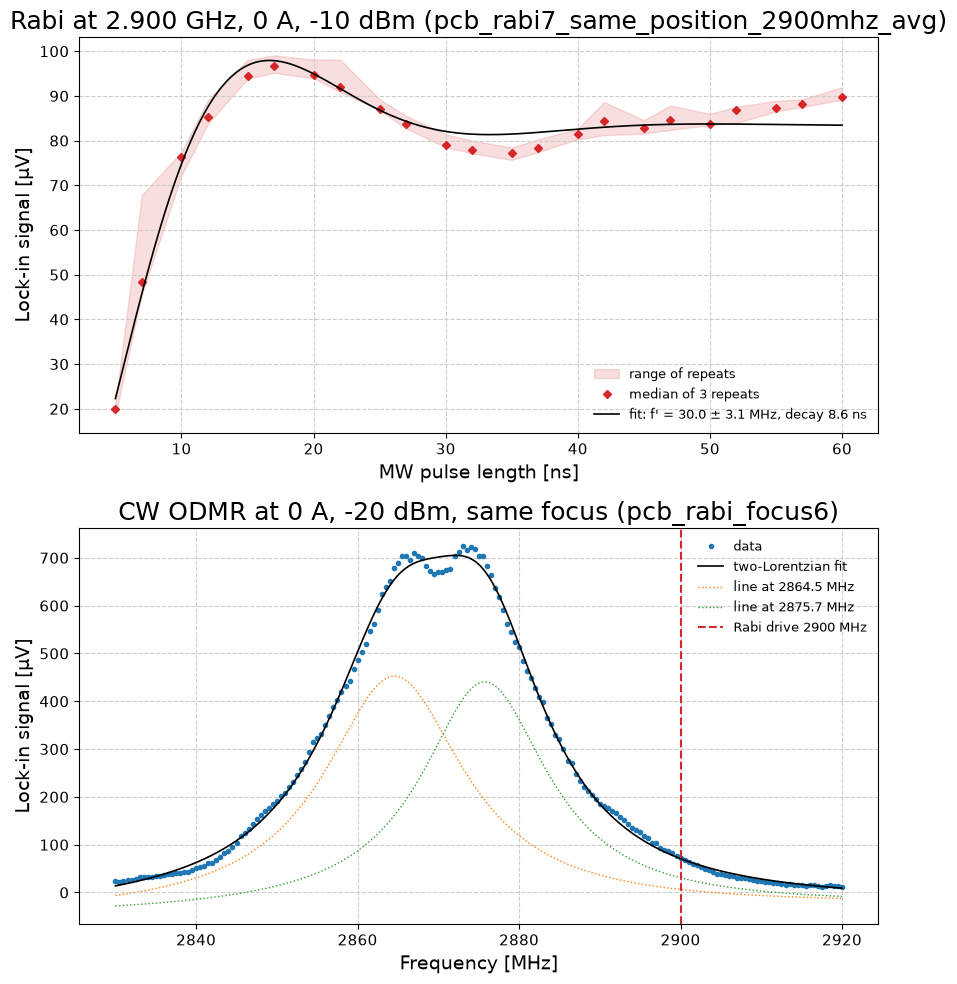

In [17]:
# Uses s_all / t_avg / fits_avg from the repeats cell above.
CW_DIR = Path(r"D:\cw_odmr_lock_in")
cw_name = "pcb_rabi_focus6"  # 0 A, -20 dBm, 2830-2920 MHz, same focus as the pcb_rabi6/7 runs
DRIVE_MHZ = 2900.0


def load_cw_full_repeats(name):
    """Stack the full-length sweep-average repeats of a cw_odmr_lock_in run (partial ones skipped)."""
    run_dir = CW_DIR / name
    pat = re.compile(rf"{re.escape(name)}_repeat(\d+)_x\.npy")
    ids = sorted(int(m.group(1)) for p in run_dir.glob("*_repeat*_x.npy") if (m := pat.fullmatch(p.name)))
    grids = {k: np.load(run_dir / f"{name}_repeat{k}_freqs_hz.npy") for k in ids}
    freqs = max(grids.values(), key=len)
    keep = [k for k in ids if len(grids[k]) == len(freqs)]
    xs = np.stack([np.load(run_dir / f"{name}_repeat{k}_x.npy") for k in keep])
    ys = np.stack([np.load(run_dir / f"{name}_repeat{k}_y.npy") for k in keep])
    return freqs, xs, ys, keep


def lorentz(f, center, fwhm):
    return (fwhm / 2) ** 2 / ((f - center) ** 2 + (fwhm / 2) ** 2)


def two_lines(f, offset, slope, a1, c1, w1, a2, c2, w2):
    return offset + slope * (f - 2875) + a1 * lorentz(f, c1, w1) + a2 * lorentz(f, c2, w2)


# --- CW ODMR at 0 A: project on its main X/Y direction, peak positive, two-Lorentzian fit
cw_f_hz, cw_x, cw_y, cw_used = load_cw_full_repeats(cw_name)
cw_f = cw_f_hz / 1e6
cx, cy = cw_x.mean(0), cw_y.mean(0)
cw_axis, _ = principal_axis(cx, cy)
cw_s = (cx * cw_axis[0] + cy * cw_axis[1]) * 1e6
if abs(cw_s.max() - np.median(cw_s)) < abs(cw_s.min() - np.median(cw_s)):
    cw_s = -cw_s
base = np.median(np.r_[cw_s[:10], cw_s[-10:]])
height = cw_s.max() - base
p_cw, c_cw = curve_fit(two_lines, cw_f, cw_s,
                       p0=[base, 0, height / 1.5, 2864.5, 15, height / 1.5, 2875.7, 15], maxfev=50000)
e_cw = np.sqrt(np.diag(c_cw))
lines_cw = sorted([(p_cw[3], e_cw[3], abs(p_cw[4])), (p_cw[6], e_cw[6], abs(p_cw[7]))])
print(f"{cw_name}: repeat(s) {cw_used}, {len(cw_f)} points; two-line fit: "
      + ", ".join(f"{c:.1f} +/- {e:.1f} MHz (FWHM {w:.1f})" for c, e, w in lines_cw)
      + f"; midpoint {(lines_cw[0][0] + lines_cw[1][0]) / 2:.1f} MHz")

# --- Rabi median and its fit
p_med, e_med, rms_med = fits_avg["median"]
f_gen = p_med[3]
print(f"median of {len(s_all)} repeats: f' = {f_gen:.1f} +/- {e_med[3]:.1f} MHz, decay {p_med[2]:.1f} "
      f"+/- {e_med[2]:.1f} ns, rms {rms_med:.2f} µV")
for label, centre in (("nearer line", lines_cw[1][0]), ("line midpoint", (lines_cw[0][0] + lines_cw[1][0]) / 2)):
    delta = DRIVE_MHZ - centre
    f_r = np.sqrt(max(f_gen ** 2 - delta ** 2, 0))
    print(f"  drive {DRIVE_MHZ:.0f} MHz vs {label} {centre:.1f} MHz: Δ = {delta:+.1f} MHz -> "
          f"f_R = sqrt(f'^2 - Δ^2) ≈ {f_r:.1f} MHz")

fig, axs = plt.subplot_mosaic([["rabi"], ["cw"]], figsize=(9, 10))
t_fine = np.linspace(t_avg.min(), t_avg.max(), 500)
axs["rabi"].fill_between(t_avg, s_all.min(0), s_all.max(0), color="C3", alpha=0.15, label="range of repeats")
axs["rabi"].plot(t_avg, np.median(s_all, 0), "D", ms=4, color="C3", label=f"median of {len(s_all)} repeats")
axs["rabi"].plot(t_fine, detuned_rabi(t_fine, *p_med), "-", color="k", lw=1.2,
                 label=f"fit: f' = {f_gen:.1f} ± {e_med[3]:.1f} MHz, decay {p_med[2]:.1f} ns")
axs["rabi"].set_xlabel("MW pulse length [ns]")
axs["rabi"].set_ylabel("Lock-in signal [µV]")
axs["rabi"].set_title("Rabi at 2.900 GHz, 0 A, -10 dBm (pcb_rabi7_same_position_2900mhz_avg)")
axs["rabi"].legend(fontsize=9)

f_fine = np.linspace(cw_f.min(), cw_f.max(), 1000)
axs["cw"].plot(cw_f, cw_s, "o", ms=3, color="C0", label="data")
axs["cw"].plot(f_fine, two_lines(f_fine, *p_cw), "-", color="k", lw=1.2, label="two-Lorentzian fit")
for k, color in ((3, "C1"), (6, "C2")):
    axs["cw"].plot(f_fine, p_cw[0] + p_cw[1] * (f_fine - 2875) + p_cw[k - 1] * lorentz(f_fine, p_cw[k], p_cw[k + 1]),
                   ":", color=color, lw=1, label=f"line at {p_cw[k]:.1f} MHz")
axs["cw"].axvline(DRIVE_MHZ, color="C3", lw=1.5, ls="--", label=f"Rabi drive {DRIVE_MHZ:.0f} MHz")
axs["cw"].set_xlabel("Frequency [MHz]")
axs["cw"].set_ylabel("Lock-in signal [µV]")
axs["cw"].set_title(f"CW ODMR at 0 A, -20 dBm, same focus ({cw_name})")
axs["cw"].legend(fontsize=9)
fig.tight_layout()
plt.show()


## Rabi fit summing the two 0 A lines (each 0 A run fitted separately)

Instead of one free oscillation frequency, each run is fitted with the sum of the detuned Rabi responses to the two 0 A lines from the CW fit above. Line k sits at detuning Δ_k from the drive and oscillates at f'_k = sqrt(f_R² + Δ_k²) with amplitude f_R²/f'_k², weighted by its CW peak height; one exponential decay stands in for the line widths and the microwave-field spread. Free parameters: offset, amplitude, f_R, decay, and a small time offset t0. The 2.900 GHz point uses the median of the three repeats.

**Result: fitted separately, f_R is not determined.** When f_R is well below both detunings, each line oscillates at f'_k ≈ |Δ_k|, set by the drive frequency and not by f_R, and f_R only scales the amplitude by f_R²/f'_k² -- which the free amplitude absorbs. So the detuned runs fit well (rms 1.6-3.4 µV) with f_R anywhere from the 0.5 MHz bound to ~15 MHz (errors of 6-80 MHz). The ~30 MHz oscillation at 2.900 GHz is explained by the two lines at Δ = +24 and +36 MHz together, without needing a large f_R. The near-line runs (2855, 2875, 2877 MHz) aren't fitted well by this model (no fringe, 5 ns steps; t0 hits its bound). Constraining f_R needs the amplitude to be shared between runs (same focus and collection), so the plateau height relative to the near-line runs measures f_R²/f'².

lines: 2864.5 and 2875.7 MHz, weights 0.51 / 0.49


2845 MHz pcb_rabi7_same_position_2845mhz_test: Δ = -19.5, -30.7 MHz -> f_R = 0.5 +/- 61.3 MHz, decay 9.9 +/- 0.6 ns, t0 +3.2 ns, rms 1.45 µV


2855 MHz pcb_rabi6_further_detuned_less: Δ = -9.5, -20.7 MHz -> f_R = 0.5 +/- 109.2 MHz, decay 13.3 +/- 22.4 ns, t0 +5.0 ns, rms 7.30 µV


2875 MHz pcb_rabi6_further: Δ = +10.5, -0.7 MHz -> f_R = 1.5 +/- 38.1 MHz, decay 11.8 +/- 43.7 ns, t0 -5.0 ns, rms 5.27 µV


2877 MHz pcb_rabi6_further_detuned: Δ = +12.5, +1.3 MHz -> f_R = 0.5 +/- 42.9 MHz, decay 12.7 +/- 12.6 ns, t0 -5.0 ns, rms 1.83 µV


2895 MHz pcb_rabi6_further_detuned_more: Δ = +30.5, +19.3 MHz -> f_R = 0.5 +/- 81.8 MHz, decay 9.8 +/- 0.8 ns, t0 +3.2 ns, rms 1.83 µV


2900 MHz pcb_rabi7_same_position_2900mhz: Δ = +35.5, +24.3 MHz -> f_R = 0.5 +/- 161.8 MHz, decay 11.0 +/- 1.5 ns, t0 +2.8 ns, rms 3.34 µV


2900 MHz pcb_rabi7_same_position_2900mhz_repeat: Δ = +35.5, +24.3 MHz -> f_R = 13.0 +/- 6.5 MHz, decay 9.6 +/- 1.0 ns, t0 +3.4 ns, rms 2.53 µV


2900 MHz pcb_rabi7_same_position_2900mhz_avg (median): Δ = +35.5, +24.3 MHz -> f_R = 12.1 +/- 8.1 MHz, decay 9.1 +/- 1.0 ns, t0 +3.1 ns, rms 2.88 µV


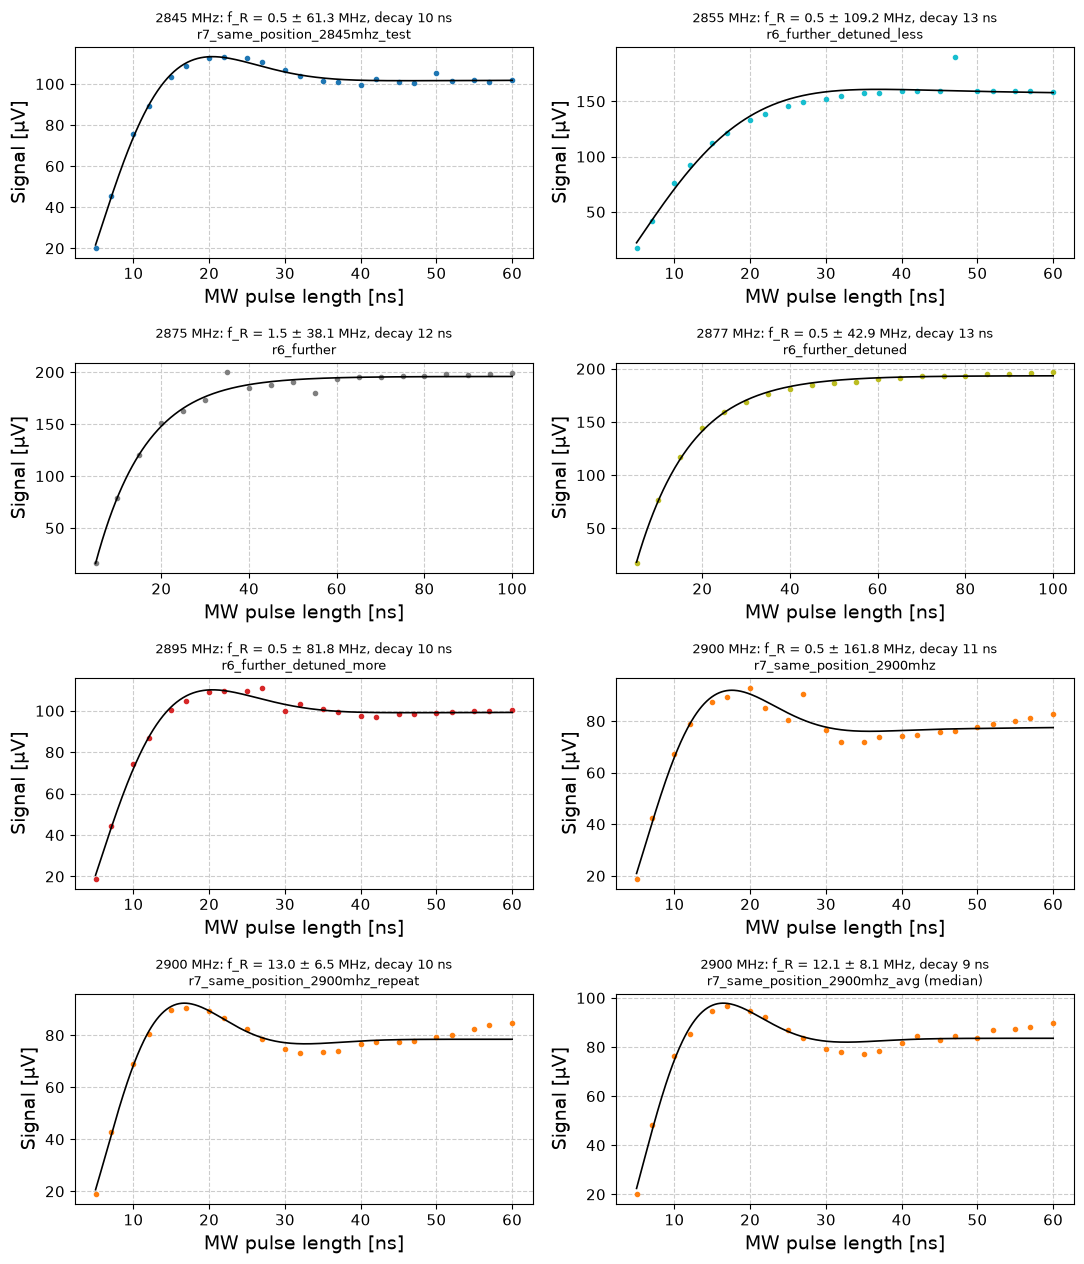

In [18]:
# Uses lines_cw / p_cw (0 A CW fit), s_all / t_avg (2900 MHz repeats), zero_a and projected() from cells above.
LINE_PEAKS = [(p_cw[3], p_cw[2]), (p_cw[6], p_cw[5])]   # (centre MHz, fitted Lorentzian height)


def two_peak_rabi(t, offset, amp, f_r, tau, t0, drive):
    """Sum of the detuned Rabi responses to the two 0 A lines: each line k (detuning Δ_k from the drive,
    weight = its CW peak height) oscillates at f'_k = sqrt(f_R² + Δ_k²) with amplitude f_R²/f'_k²;
    a common exponential decay tau stands in for the line widths and microwave-field spread."""
    total_h = sum(h for _, h in LINE_PEAKS)
    out = np.zeros_like(t, dtype=float)
    for centre, h in LINE_PEAKS:
        fp = np.sqrt(f_r ** 2 + (drive - centre) ** 2)
        out += h / total_h * f_r ** 2 / fp ** 2 * (1 - np.exp(-(t - t0) / tau) * np.cos(2 * np.pi * fp * 1e-3 * (t - t0))) / 2
    return offset + amp * out


def fit_two_peak(t, s, drive):
    """Fit two_peak_rabi at a fixed drive frequency; try several starting f_R, keep the best."""
    best = None
    for fr0 in (5, 10, 15, 20, 30):
        try:
            p, cov = curve_fit(lambda tt, *q: two_peak_rabi(tt, *q, drive), t, s,
                               p0=[s[0], 2 * (s[-1] - s[0]), fr0, 10, 0],
                               bounds=([-np.inf, 0, 0.5, 1, -5], [np.inf, np.inf, 80, 500, 5]), maxfev=20000)
        except RuntimeError:
            continue
        rms = np.sqrt(np.mean((s - two_peak_rabi(t, *p, drive)) ** 2))
        if best is None or rms < best[2]:
            best = (p, np.sqrt(np.diag(cov)), rms)
    return best


tp_runs = {name: (r["mw_us"] * 1e3, projected(r)[0], float(r["metadata"]["freq_hz"]) / 1e6)
           for name, r in zero_a.items() if r["mw_us"].min() * 1e3 < 60}  # skip the 60-120 ns _cont piece
tp_runs["pcb_rabi7_same_position_2900mhz_avg (median)"] = (t_avg, np.median(s_all, 0), 2900.0)

print(f"lines: {LINE_PEAKS[0][0]:.1f} and {LINE_PEAKS[1][0]:.1f} MHz, weights "
      f"{LINE_PEAKS[0][1] / (LINE_PEAKS[0][1] + LINE_PEAKS[1][1]):.2f} / "
      f"{LINE_PEAKS[1][1] / (LINE_PEAKS[0][1] + LINE_PEAKS[1][1]):.2f}")
tp_fits = {}
for name, (t, s, drive) in tp_runs.items():
    res = fit_two_peak(t, s, drive)
    if res is None:
        print(f"{drive:.0f} MHz {name}: fit did not converge")
        continue
    tp_fits[name] = res
    p, e, rms = res
    deltas = ", ".join(f"{drive - c:+.1f}" for c, _ in LINE_PEAKS)
    print(f"{drive:.0f} MHz {name}: Δ = {deltas} MHz -> f_R = {p[2]:.1f} +/- {e[2]:.1f} MHz, "
          f"decay {p[3]:.1f} +/- {e[3]:.1f} ns, t0 {p[4]:+.1f} ns, rms {rms:.2f} µV")

n_plots = len(tp_fits)
fig, axs = plt.subplots((n_plots + 1) // 2, 2, figsize=(11, 3.2 * ((n_plots + 1) // 2)), squeeze=False)
for ax, (name, (p, e, rms)) in zip(axs.flat, sorted(tp_fits.items(), key=lambda kv: tp_runs[kv[0]][2])):
    t, s, drive = tp_runs[name]
    t_fine = np.linspace(t.min(), t.max(), 500)
    ax.plot(t, s, "o", ms=3, color=ZERO_A_COLORS.get(round(drive), "k"))
    ax.plot(t_fine, two_peak_rabi(t_fine, *p, drive), "-", color="k", lw=1.2)
    ax.set_title(f"{drive:.0f} MHz: f_R = {p[2]:.1f} ± {e[2]:.1f} MHz, decay {p[3]:.0f} ns\n"
                 f"{name.replace('pcb_rabi', 'r')}", fontsize=9)
    ax.set_xlabel("MW pulse length [ns]")
    ax.set_ylabel("Signal [µV]")
for ax in axs.flat[n_plots:]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()


## Joint two-line fit with a shared amplitude

All 0 A, -10 dBm runs at this focus fitted together with the two-line detuned Rabi model. Shared by every run: amplitude, offset, t0 (same focus and collection, so the same full signal), and the dephasing. The dephasing is physical rather than a free exponential: a relative spread sigma of f_R (microwave-field spread) and a spread gamma of Δ (line width), which give each line a spread of f' of sigma·f_R²/f' and gamma·|Δ|/f' (Gaussian envelope). A free per-run decay would let a run rise smoothly whatever f_R is, which is why separate fits couldn't see f_R. Two versions: one f_R for every run, and one f_R per run (the PCB match, and so the field at the diamond, changes with frequency). The 2.900 GHz run is the median of the three repeats; the two earlier single 2.900 GHz runs are left out so that frequency isn't counted three times. Robust (soft-L1) loss, so single glitched points don't pull the fit.

**Result: no single f_R with a Gaussian spread fits all the runs.** The detuned runs (2845, 2895, 2900 MHz) are fitted with f_R ≈ 15-20 MHz, but with one shared amplitude that predicts the near-line runs (2855, 2875, 2877 MHz) saturating by ~20 ns, while they actually rise slowly and are still climbing at 40-60 ns (rms 10-21 µV there, vs ~5 µV for the detuned runs). With f_R free per run, the near-line runs drop to ~7 MHz with large errors. The fitted spreads (sigma ~100-150 %, gamma ~30-40 MHz) are at the edge of what the model can represent, and the fits are over-damped (the dip at ~35 ns at 2.900 GHz is missed). This points to a broad distribution of f_R across the diamond with many weak-field spins: those dominate the slow near-line rise, but contribute little when detuned (their weight goes as f_R²/Δ²), so the detuned runs mostly see the strong-field spins, at f_R ≈ 15-20 MHz.


one f_R for all runs: amplitude 386 +/- 28 µV, offset 24.4 µV, t0 +5.0 +/- 1.4 ns, field spread sigma 99 +/- 145 %, line spread gamma 31.4 +/- 20.3 MHz; rms 13.72 µV over 132 points
  2845 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 27.7, 36.5 MHz), rms 5.36 µV  [r7_same_position_2845mhz_test]
  2855 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 21.8, 28.6 MHz), rms 16.37 µV  [r6_further_detuned_less]
  2875 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 22.3, 19.7 MHz), rms 20.84 µV  [r6_further]
  2877 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 23.3, 19.7 MHz), rms 20.05 µV  [r6_further_detuned]
  2895 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 36.3, 27.5 MHz), rms 4.89 µV  [r6_further_detuned_more]
  2900 MHz: f_R = 19.7 +/- 2.6 MHz (f' = 40.5, 31.2 MHz), rms 5.73 µV  [r7_same_position_2900mhz_avg (median)]



f_R per run: amplitude 544 +/- 281 µV, offset 21.4 µV, t0 +4.2 +/- 0.8 ns, field spread sigma 149 +/- 370 %, line spread gamma 27.0 +/- 21.2 MHz; rms 8.85 µV over 132 points
  2845 MHz: f_R = 15.6 +/- 5.7 MHz (f' = 25.0, 34.5 MHz), rms 4.56 µV  [r7_same_position_2845mhz_test]
  2855 MHz: f_R = 13.7 +/- 7.8 MHz (f' = 16.7, 24.8 MHz), rms 14.85 µV  [r6_further_detuned_less]
  2875 MHz: f_R = 6.9 +/- 9.8 MHz (f' = 12.6, 7.0 MHz), rms 10.52 µV  [r6_further]
  2877 MHz: f_R = 7.7 +/- 10.5 MHz (f' = 14.7, 7.8 MHz), rms 8.80 µV  [r6_further_detuned]
  2895 MHz: f_R = 15.2 +/- 5.5 MHz (f' = 34.0, 24.5 MHz), rms 4.54 µV  [r6_further_detuned_more]
  2900 MHz: f_R = 16.0 +/- 5.3 MHz (f' = 38.9, 29.1 MHz), rms 4.92 µV  [r7_same_position_2900mhz_avg (median)]


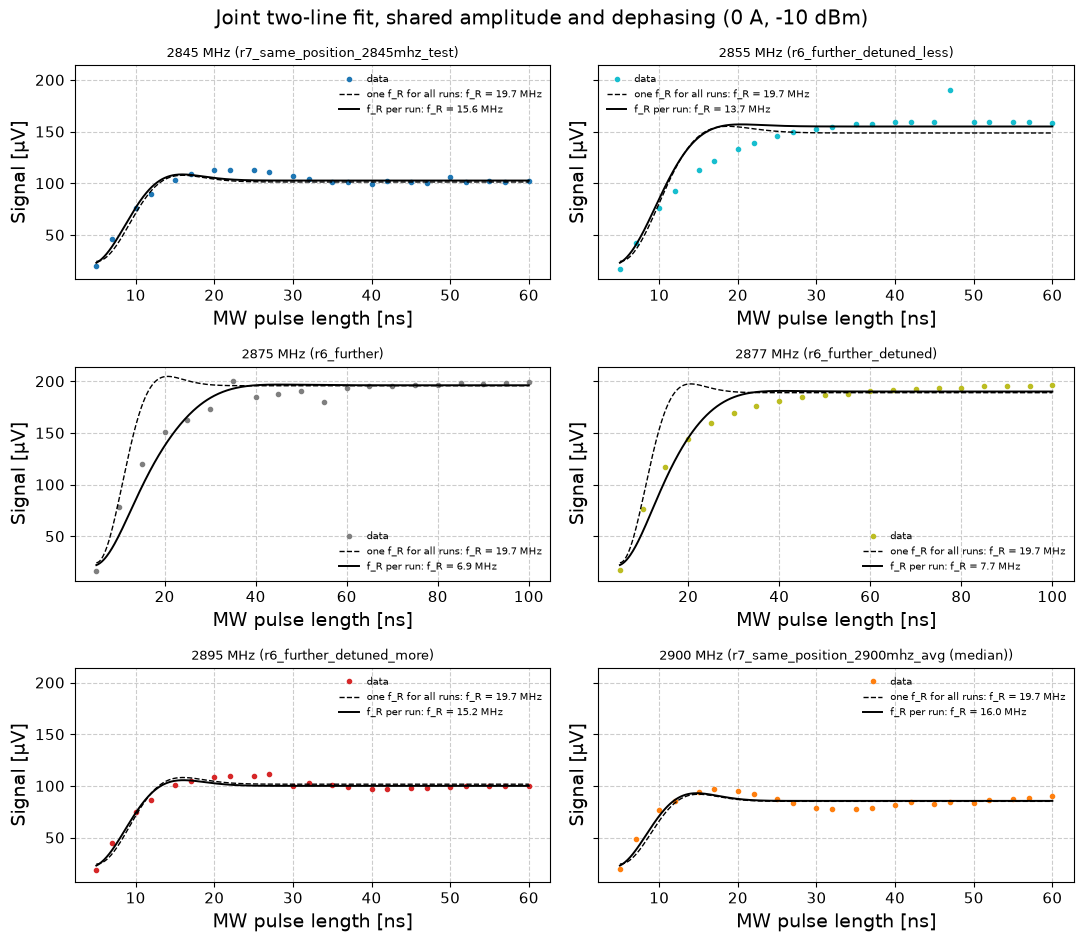

In [19]:
# Joint fit of the 0 A runs (tp_runs, LINE_PEAKS from the cells above).
# A free exponential decay lets a run rise smoothly whatever f_R is (that's why per-run fits can't see f_R),
# so here the dephasing comes from the physical spreads instead, which scale with f_R and Δ:
#   relative spread sigma of f_R (microwave-field spread)  -> spread of f' = sigma * f_R² / f'
#   spread gamma of Δ (line width)                          -> spread of f' = gamma * |Δ| / f'
# with a Gaussian envelope exp(-(2π t δf')²/2). Shared by all runs: amplitude, offset, t0, sigma, gamma;
# f_R either shared or per run (the PCB match, and so the field at the diamond, changes with frequency).
from scipy.optimize import least_squares


def two_peak_rabi_dephased(t, offset, amp, f_r, sigma, gamma, t0, drive):
    total_h = sum(h for _, h in LINE_PEAKS)
    te = (t - t0) * 1e-3  # µs, so f in MHz
    out = np.zeros_like(t, dtype=float)
    for centre, h in LINE_PEAKS:
        delta = drive - centre
        fp = np.sqrt(f_r ** 2 + delta ** 2)
        spread = np.hypot(sigma * f_r ** 2, gamma * delta) / fp
        out += h / total_h * f_r ** 2 / fp ** 2 * (
            1 - np.exp(-0.5 * (2 * np.pi * spread * te) ** 2) * np.cos(2 * np.pi * fp * te)) / 2
    return offset + amp * out


joint_names = [n for n in sorted(tp_runs, key=lambda n: tp_runs[n][2])
               if n not in ("pcb_rabi7_same_position_2900mhz", "pcb_rabi7_same_position_2900mhz_repeat")]
n_runs = len(joint_names)
N_SHARED = 5  # offset, amp, sigma, gamma, t0


def unpack(q, shared_fr):
    offset, amp, sigma, gamma, t0 = q[:N_SHARED]
    fr = np.full(n_runs, q[N_SHARED]) if shared_fr else np.asarray(q[N_SHARED:N_SHARED + n_runs])
    return offset, amp, sigma, gamma, t0, fr


def run_model(q, shared_fr, k, t):
    offset, amp, sigma, gamma, t0, fr = unpack(q, shared_fr)
    return two_peak_rabi_dephased(t, offset, amp, fr[k], sigma, gamma, t0, tp_runs[joint_names[k]][2])


def joint_resid(q, shared_fr):
    return np.concatenate([run_model(q, shared_fr, k, tp_runs[n][0]) - tp_runs[n][1]
                           for k, n in enumerate(joint_names)])


def fit_joint(shared_fr):
    n_fr = 1 if shared_fr else n_runs
    lo = [-np.inf, 0, 0, 0, -5] + [0.5] * n_fr
    hi = [np.inf, np.inf, 2, 40, 5] + [80] * n_fr
    best = None
    for fr0 in (5, 10, 20, 30):
        for sg0, gm0 in ((0.3, 5), (0.8, 10)):
            q0 = [0, 500, sg0, gm0, 0] + [fr0] * n_fr
            r = least_squares(joint_resid, q0, args=(shared_fr,), bounds=(lo, hi), loss="soft_l1", f_scale=3.0)
            if best is None or r.cost < best.cost:
                best = r
    dof = max(len(best.fun) - len(best.x), 1)
    cov = np.linalg.pinv(best.jac.T @ best.jac) * np.sum(best.fun ** 2) / dof
    return best.x, np.sqrt(np.diag(cov)), np.sqrt(np.mean(best.fun ** 2))


joint_fits = {}
for label, shared_fr in (("one f_R for all runs", True), ("f_R per run", False)):
    q, e, rms = fit_joint(shared_fr)
    joint_fits[label] = (q, e, shared_fr)
    offset, amp, sigma, gamma, t0, fr = unpack(q, shared_fr)
    _, e_amp, e_sigma, e_gamma, e_t0, e_fr = unpack(e, shared_fr)
    print(f"\n{label}: amplitude {amp:.0f} +/- {e_amp:.0f} µV, offset {offset:.1f} µV, t0 {t0:+.1f} +/- {e_t0:.1f} ns, "
          f"field spread sigma {sigma * 100:.0f} +/- {e_sigma * 100:.0f} %, line spread gamma {gamma:.1f} +/- {e_gamma:.1f} MHz; "
          f"rms {rms:.2f} µV over {len(joint_resid(q, shared_fr))} points")
    for k, name in enumerate(joint_names):
        t, s, drive = tp_runs[name]
        r_k = np.sqrt(np.mean((run_model(q, shared_fr, k, t) - s) ** 2))
        fps = ", ".join(f"{np.sqrt(fr[k] ** 2 + (drive - c) ** 2):.1f}" for c, _ in LINE_PEAKS)
        print(f"  {drive:.0f} MHz: f_R = {fr[k]:.1f} +/- {e_fr[k]:.1f} MHz (f' = {fps} MHz), rms {r_k:.2f} µV"
              f"  [{name.replace('pcb_rabi', 'r')}]")

fig, axs = plt.subplots((n_runs + 1) // 2, 2, figsize=(11, 3.2 * ((n_runs + 1) // 2)), sharey=True, squeeze=False)
for k, (ax, name) in enumerate(zip(axs.flat, joint_names)):
    t, s, drive = tp_runs[name]
    t_fine = np.linspace(t.min(), t.max(), 500)
    ax.plot(t, s, "o", ms=3, color=ZERO_A_COLORS.get(round(drive), "k"), label="data")
    for (label, (q, e, shared_fr)), style in zip(joint_fits.items(), ("--", "-")):
        fr_k = unpack(q, shared_fr)[5][k]
        ax.plot(t_fine, run_model(q, shared_fr, k, t_fine), style, color="k",
                lw=1 if style == "--" else 1.4, label=f"{label}: f_R = {fr_k:.1f} MHz")
    ax.set_title(f"{drive:.0f} MHz ({name.replace('pcb_rabi', 'r')})", fontsize=9)
    ax.set_xlabel("MW pulse length [ns]")
    ax.set_ylabel("Signal [µV]")
    ax.legend(fontsize=7)
for ax in axs.flat[n_runs:]:
    ax.set_visible(False)
fig.suptitle("Joint two-line fit, shared amplitude and dephasing (0 A, -10 dBm)")
fig.tight_layout()
plt.show()


## Joint fit with an explicit f_R distribution

Same six runs and two-line model as above, but instead of one f_R with a Gaussian spread, f_R is binned (16 log-spaced bins, 1-40 MHz) and each bin's weight -- how much of the full-contrast signal comes from spins with that f_R -- is fitted, shared by all runs. The same field distribution applies at every drive frequency (no per-frequency PCB coupling). Shared line spread gamma, time offset t0 and offset; the weights come from a non-negative least-squares solve with a small smoothness penalty, gamma and t0 from a grid search. A second pass drops gross outliers (glitched points).

**Result: this doesn't fit either.** The overall rms is ~14 µV (10-25 µV per run), against ~1-3 µV of noise. The fit pushes t0 to ~7 ns and the offset to ~55 µV, i.e. it gives up on the first two points of every run (measured ~20 and ~45 µV at 5 and 7.5 ns), and still over-shoots the detuned runs' fringe and under-shoots the 2855 MHz plateau. The fitted distribution (median ~7-8 MHz, 10-90 % range ~3-30 MHz) shouldn't be trusted. Tried outside the notebook as well: fixing the offset at 0 makes it worse (rms 22 µV), and letting the field strength scale per drive frequency (PCB coupling) only gets to ~11 µV. So the shared-amplitude picture -- the same spins, the same full contrast, just a different drive frequency -- doesn't hold together across these six runs with this model; something not in it (line shape at the spin level rather than the power-broadened CW shape, contrast that depends on frequency, or drift between the pcb_rabi6 and pcb_rabi7 sessions) matters at the 10 µV level. A direct way to separate f_R from Δ is a power series at one detuned frequency: f'² = f_R²(P) + Δ² with f_R ∝ sqrt(P).

best: line spread gamma 0 MHz, t0 +6.5 ns, offset 54.5 µV; rms 14.26 µV over 132 points (0 outliers dropped)
total full-contrast signal 359 µV; weighted mean f_R 13.6 MHz, median 8.1 MHz, 10-90 % range 3.4-29.0 MHz
f_R bins [MHz]:   1.0   1.3   1.6   2.1   2.7   3.4   4.4   5.6   7.2   9.1  11.7  15.0  19.1  24.5  31.3  40.0
weight   [%]  :   0.0   0.0   0.2   1.0   2.9   5.7   9.0  12.0  13.3  12.2   9.1   6.6   6.6   7.5   5.9   8.0


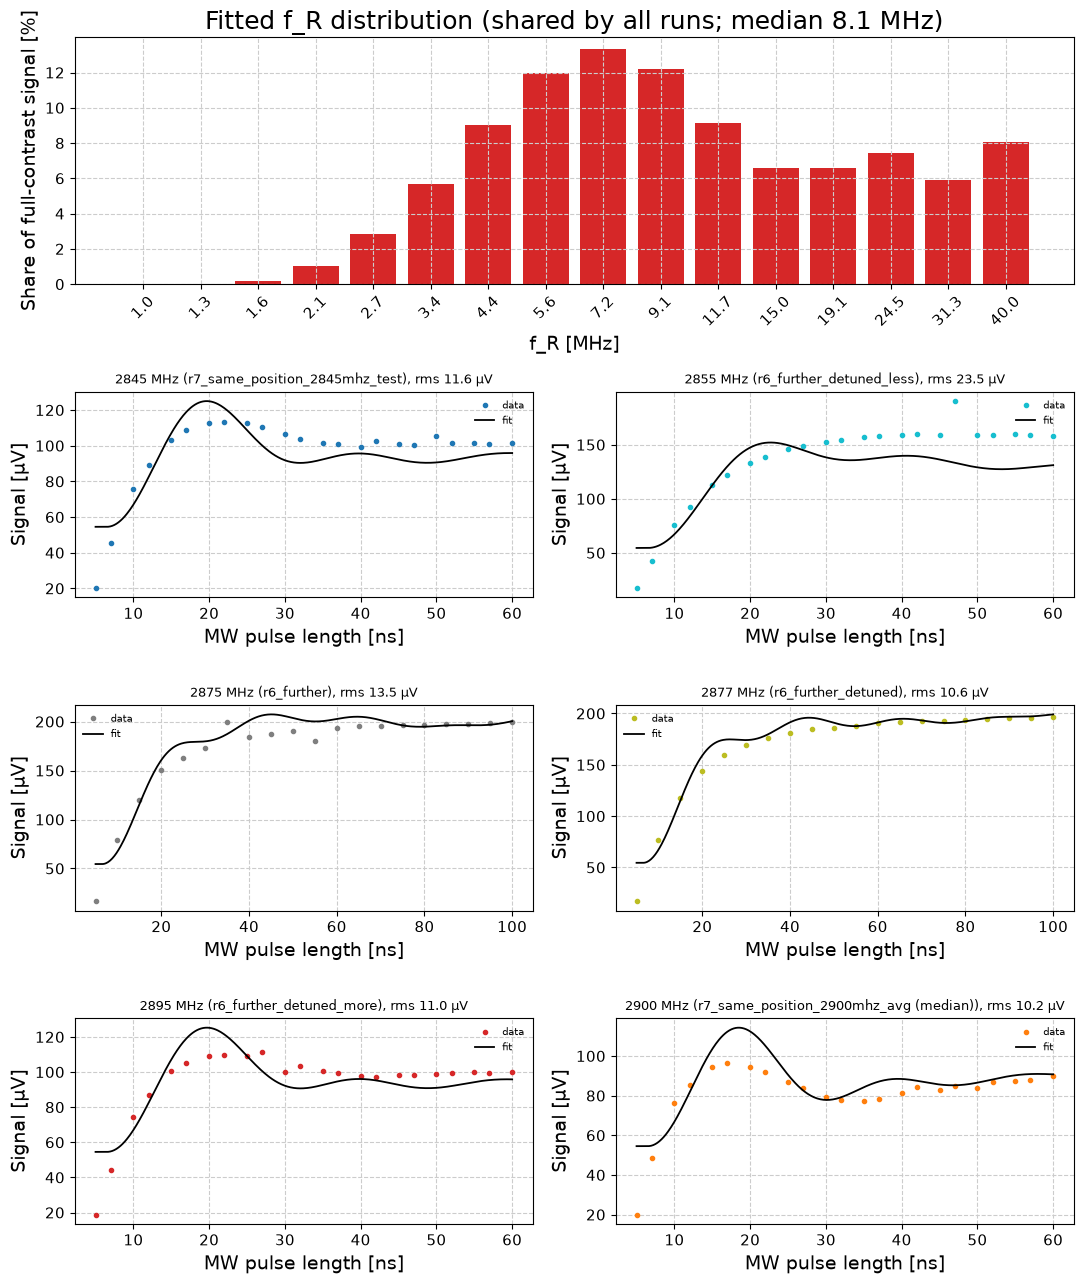

In [20]:
# Joint fit with an explicit f_R distribution (joint_names, tp_runs, LINE_PEAKS from the cells above).
# f_R is binned on a log grid; each bin's weight (µV of full-contrast signal from spins with that f_R) is
# shared by all runs and fitted >= 0. For fixed line spread gamma and time offset t0 the model is linear in the
# weights, so they come from a non-negative least-squares solve (with a small smoothness penalty), and
# gamma and t0 are found by a grid search.
from scipy.optimize import nnls

FR_BINS = np.geomspace(1, 40, 16)          # MHz
Z_BIN = np.linspace(-1, 1, 5) * 0.12       # within-bin spread (about half the log spacing), smooths the bins
SMOOTH = 0.3                               # weight of the second-difference penalty (µV units)


def bin_response(t, drive, gamma, t0):
    """(len(t), n_bins) response of each f_R bin, unit weight, summed over the two lines."""
    total_h = sum(h for _, h in LINE_PEAKS)
    te = np.clip(t - t0, 0, None)[:, None, None] * 1e-3
    fr = (FR_BINS[None, :, None] * (1 + Z_BIN[None, None, :]))
    out = 0
    for centre, h in LINE_PEAKS:
        delta = drive - centre
        fp = np.sqrt(fr ** 2 + delta ** 2)
        env = np.exp(-0.5 * (2 * np.pi * gamma * abs(delta) / fp * te) ** 2)
        out = out + h / total_h * (fr ** 2 / fp ** 2 * (1 - env * np.cos(2 * np.pi * fp * te)) / 2).mean(axis=2)
    return out


def design(gamma, t0):
    blocks = [bin_response(tp_runs[n][0], tp_runs[n][2], gamma, t0) for n in joint_names]
    m = np.vstack(blocks)
    ones = np.ones((len(m), 1))
    return np.hstack([m, ones, -ones])  # offset as the difference of two non-negative columns


s_joint = np.concatenate([tp_runs[n][1] for n in joint_names])
n_bins = len(FR_BINS)
d2 = np.zeros((n_bins - 2, n_bins + 2))
for i in range(n_bins - 2):
    d2[i, i:i + 3] = [1, -2, 1]


def solve(gamma, t0, keep):
    m = design(gamma, t0)
    a = np.vstack([m[keep], SMOOTH * d2])
    b = np.concatenate([s_joint[keep], np.zeros(len(d2))])
    w, _ = nnls(a, b, maxiter=5000)
    return w, m @ w


keep = np.ones(len(s_joint), bool)
for pass_ in range(2):  # second pass drops gross outliers (glitched points) found in the first
    grid = [(np.sqrt(np.mean((solve(g, t0, keep)[1] - s_joint)[keep] ** 2)), g, t0)
            for g in np.arange(0, 32, 2.0) for t0 in np.arange(-2, 10.5, 0.5)]
    rms_best, gamma_best, t0_best = min(grid)
    w_best, pred = solve(gamma_best, t0_best, keep)
    resid = pred - s_joint
    mad = np.median(np.abs(resid[keep] - np.median(resid[keep])))
    keep = np.abs(resid) < 6 * 1.4826 * mad if pass_ == 0 else keep
print(f"best: line spread gamma {gamma_best:.0f} MHz, t0 {t0_best:+.1f} ns, offset {w_best[-2] - w_best[-1]:.1f} µV; "
      f"rms {rms_best:.2f} µV over {keep.sum()} points ({(~keep).sum()} outliers dropped)")

weights = w_best[:n_bins]
frac = weights / weights.sum()
mean_fr = np.sum(frac * FR_BINS)
cdf = np.cumsum(frac)
print(f"total full-contrast signal {weights.sum():.0f} µV; weighted mean f_R {mean_fr:.1f} MHz, "
      f"median {np.interp(0.5, cdf, FR_BINS):.1f} MHz, 10-90 % range "
      f"{np.interp(0.1, cdf, FR_BINS):.1f}-{np.interp(0.9, cdf, FR_BINS):.1f} MHz")
print("f_R bins [MHz]:", " ".join(f"{f:5.1f}" for f in FR_BINS))
print("weight   [%]  :", " ".join(f"{100 * x:5.1f}" for x in frac))

offset_fit = w_best[-2] - w_best[-1]
start = 0
fig = plt.figure(figsize=(11, 13))
gs = fig.add_gridspec(4, 2, height_ratios=[1.2, 1, 1, 1])
ax_d = fig.add_subplot(gs[0, :])
ax_d.bar(np.arange(n_bins), 100 * frac, color="C3")
ax_d.set_xticks(np.arange(n_bins), [f"{f:.1f}" for f in FR_BINS], rotation=45)
ax_d.set_xlabel("f_R [MHz]")
ax_d.set_ylabel("Share of full-contrast signal [%]")
ax_d.set_title(f"Fitted f_R distribution (shared by all runs; median {np.interp(0.5, cdf, FR_BINS):.1f} MHz)")
for k, name in enumerate(joint_names):
    t, s, drive = tp_runs[name]
    n = len(t)
    ax = fig.add_subplot(gs[1 + k // 2, k % 2])
    kk = keep[start:start + n]
    ax.plot(t[kk], s[kk], "o", ms=3, color=ZERO_A_COLORS.get(round(drive), "k"), label="data")
    ax.plot(t[~kk], s[~kk], "x", ms=6, color="k", label="dropped (outlier)" if (~kk).any() else None)
    t_fine = np.linspace(t.min(), t.max(), 400)
    model_fine = bin_response(t_fine, drive, gamma_best, t0_best) @ weights + offset_fit
    ax.plot(t_fine, model_fine, "-", color="k", lw=1.3, label="fit")
    rms_k = np.sqrt(np.mean((pred[start:start + n] - s)[kk] ** 2))
    ax.set_title(f"{drive:.0f} MHz ({name.replace('pcb_rabi', 'r')}), rms {rms_k:.1f} µV", fontsize=9)
    ax.set_xlabel("MW pulse length [ns]")
    ax.set_ylabel("Signal [µV]")
    ax.legend(fontsize=7)
    start += n
fig.tight_layout()
plt.show()
